# Medium Dataset 2 - CSE-CIC-IDS2018 Unsupervised Anomaly Detection

This notebook evaluates unsupervised anomaly detection methods on the CSE-CIC-IDS2018 network traffic dataset.

The analysis focuses on learning benign network behaviour and detecting DoS-GoldenEye traffic as anomalous.

## Import Libraries

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif, VarianceThreshold
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.covariance import EmpiricalCovariance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import optuna

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("Optuna:", optuna.__version__)

Python: 3.12.7
NumPy: 2.5.3
Pandas: 3.0.6
TensorFlow: 2.21.0
Optuna: 5.0.0


c:\Projects\Computer-Log-Anomaly-Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Dataset

In [2]:
DATA_PATH = Path("../data/medium/02-15-2018.csv")

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset shape:", df.shape)

Dataset shape: (1048575, 80)


## Check Labels

In [3]:
print(df["Label"].value_counts())

print("\nClass percentages:")
print(
    df["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

Label
Benign                   996077
DoS attacks-GoldenEye     41508
DoS attacks-Slowloris     10990
Name: count, dtype: int64

Class percentages:
Label
Benign                   94.9934
DoS attacks-GoldenEye     3.9585
DoS attacks-Slowloris     1.0481
Name: proportion, dtype: float64


## Check Dataset Quality

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())

numeric_df = df.select_dtypes(include=np.number)

print(
    "Infinite values:",
    np.isinf(numeric_df).sum().sum()
)

Duplicate rows: 2421
Missing values: 4921
Infinite values: 11133


## Inspect Missing and Infinite Values

The columns containing missing and infinite values are examined before applying any cleaning operation.

In [5]:
missing_by_column = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
)

print("Columns with missing values:")

print(
    missing_by_column[
        missing_by_column > 0
    ]
)

Columns with missing values:
Flow Byts/s    4921
dtype: int64


In [6]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

infinite_by_column = pd.Series(
    {
        column: np.isinf(df[column]).sum()
        for column in numeric_columns
    }
).sort_values(
    ascending=False
)

print("Columns with infinite values:")

print(
    infinite_by_column[
        infinite_by_column > 0
    ]
)

Columns with infinite values:
Flow Pkts/s    8027
Flow Byts/s    3106
dtype: int64


## Missing and Infinite Values by Class

In [7]:
problem_columns = sorted(
    set(
        missing_by_column[
            missing_by_column > 0
        ].index
    )
    |
    set(
        infinite_by_column[
            infinite_by_column > 0
        ].index
    )
)

print("Problem columns:")
print(problem_columns)

Problem columns:
['Flow Byts/s', 'Flow Pkts/s']


In [8]:
for column in problem_columns:

    print(f"\n{column}")

    print("Missing values by label:")

    print(
        df.groupby("Label")[column]
        .apply(lambda x: x.isna().sum())
    )

    if pd.api.types.is_numeric_dtype(
        df[column]
    ):

        print("Infinite values by label:")

        print(
            df.groupby("Label")[column]
            .apply(
                lambda x: np.isinf(x).sum()
            )
        )


Flow Byts/s
Missing values by label:
Label
Benign                   4921
DoS attacks-GoldenEye       0
DoS attacks-Slowloris       0
Name: Flow Byts/s, dtype: int64
Infinite values by label:
Label
Benign                   3106
DoS attacks-GoldenEye       0
DoS attacks-Slowloris       0
Name: Flow Byts/s, dtype: int64

Flow Pkts/s
Missing values by label:
Label
Benign                   0
DoS attacks-GoldenEye    0
DoS attacks-Slowloris    0
Name: Flow Pkts/s, dtype: int64
Infinite values by label:
Label
Benign                   8027
DoS attacks-GoldenEye       0
DoS attacks-Slowloris       0
Name: Flow Pkts/s, dtype: int64


## Select Benign and GoldenEye Traffic

The experiment focuses on a single attack family. Benign traffic is treated as normal behaviour and DoS-GoldenEye traffic is treated as anomalous behaviour. Slowloris traffic is excluded to avoid mixing different attack mechanisms.

In [9]:
df_binary = df[
    df["Label"].isin([
        "Benign",
        "DoS attacks-GoldenEye"
    ])
].copy()

print("Shape after label filtering:")
print(df_binary.shape)

print("\nClass distribution:")

print(
    df_binary["Label"]
    .value_counts()
)

Shape after label filtering:
(1037585, 80)

Class distribution:
Label
Benign                   996077
DoS attacks-GoldenEye     41508
Name: count, dtype: int64


## Remove Exact Duplicate Records

Exact duplicate rows are removed before dropping the timestamp. Keeping the timestamp during duplicate detection avoids incorrectly treating similar flows recorded at different times as duplicate observations.

In [10]:
duplicates_before = (
    df_binary
    .duplicated()
    .sum()
)

print(
    "Exact duplicate rows:",
    duplicates_before
)

df_binary = (
    df_binary
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "Shape after duplicate removal:",
    df_binary.shape
)

Exact duplicate rows: 1716
Shape after duplicate removal: (1035869, 80)


## Inspect Timestamp

In [11]:
print(df_binary["Timestamp"].head())

print(
    "\nTimestamp unique values:",
    df_binary["Timestamp"].nunique()
)

0    15/02/2018 08:25:18
1    15/02/2018 08:29:05
2    15/02/2018 08:29:42
3    15/02/2018 08:28:07
4    15/02/2018 08:30:56
Name: Timestamp, dtype: str

Timestamp unique values: 33862


## Remove Timestamp

The raw timestamp is removed because the objective is to model intrinsic network-flow behaviour rather than memorize when an attack occurred.

In [12]:
df_binary = df_binary.drop(
    columns=["Timestamp"]
)

print(
    "Shape after removing Timestamp:",
    df_binary.shape
)

Shape after removing Timestamp: (1035869, 79)


## Check Remaining Feature Types

The remaining columns are inspected to confirm that all predictors are numerical before constructing the anomaly detection datasets.

In [13]:
print(df_binary.dtypes.value_counts())

non_numeric_columns = df_binary.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNon-numeric columns:")
print(non_numeric_columns)

int64      54
float64    24
str         1
Name: count, dtype: int64

Non-numeric columns:
['Label']


## Convert Infinite Values to Missing Values

Infinite values cannot be used directly by the machine learning models. They are converted to missing values first. Imputation values will be learned later using only the benign training data.

In [14]:
feature_columns = [
    column
    for column in df_binary.columns
    if column != "Label"
]

df_binary[feature_columns] = df_binary[
    feature_columns
].replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Remaining infinite values:",
    np.isinf(
        df_binary[feature_columns]
        .select_dtypes(include=np.number)
    ).sum().sum()
)

print(
    "Missing values after replacing infinity:",
    df_binary[feature_columns]
    .isna()
    .sum()
    .sum()
)

Remaining infinite values: 0
Missing values after replacing infinity: 16044


## Create Binary Labels

Benign traffic is represented by 0 and DoS-GoldenEye traffic is represented by 1.

In [15]:
df_binary["target"] = (
    df_binary["Label"]
    .map({
        "Benign": 0,
        "DoS attacks-GoldenEye": 1
    })
)

print(
    df_binary["target"]
    .value_counts()
    .sort_index()
)

target
0    994414
1     41455
Name: count, dtype: int64


In [16]:
df_binary = df_binary.drop(
    columns=["Label"]
)

print("Current shape:", df_binary.shape)

Current shape: (1035869, 79)


## Separate Benign and Attack Traffic

The benign and GoldenEye samples are separated so that training can use only normal traffic while attack samples remain unseen during model fitting.

In [17]:
benign_data = (
    df_binary[
        df_binary["target"] == 0
    ]
    .drop(columns="target")
    .reset_index(drop=True)
)

attack_data = (
    df_binary[
        df_binary["target"] == 1
    ]
    .drop(columns="target")
    .reset_index(drop=True)
)

print(
    "Benign samples:",
    benign_data.shape
)

print(
    "GoldenEye samples:",
    attack_data.shape
)

Benign samples: (994414, 78)
GoldenEye samples: (41455, 78)


## Create Benign Training and Calibration Sets

A fixed benign training set is used for model fitting. A separate benign calibration set is reserved for selecting anomaly thresholds without using the final test labels.

In [18]:
TRAIN_SIZE = 100_000
CALIBRATION_SIZE = 20_000

benign_shuffled = benign_data.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

X_train_benign = benign_shuffled.iloc[
    :TRAIN_SIZE
].copy()

X_calibration_benign = benign_shuffled.iloc[
    TRAIN_SIZE:
    TRAIN_SIZE + CALIBRATION_SIZE
].copy()

benign_test_pool = benign_shuffled.iloc[
    TRAIN_SIZE + CALIBRATION_SIZE:
].copy()

print(
    "Training benign:",
    X_train_benign.shape
)

print(
    "Calibration benign:",
    X_calibration_benign.shape
)

print(
    "Remaining benign test pool:",
    benign_test_pool.shape
)

Training benign: (100000, 78)
Calibration benign: (20000, 78)
Remaining benign test pool: (874414, 78)


## Construct Test Sets

Three test sets of 30,000 records are created with anomaly rates of 0.2%, 1%, and 5%. The attack samples are nested so that higher anomaly-rate test sets include the attack samples used at lower rates.

In [19]:
TEST_SIZE = 30_000

N_ATTACK_02 = 60
N_ATTACK_1 = 300
N_ATTACK_5 = 1500

attack_shuffled = attack_data.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

benign_test_shuffled = benign_test_pool.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

In [20]:
attack_02 = attack_shuffled.iloc[
    :N_ATTACK_02
]

attack_1 = attack_shuffled.iloc[
    :N_ATTACK_1
]

attack_5 = attack_shuffled.iloc[
    :N_ATTACK_5
]

In [21]:
benign_02 = benign_test_shuffled.iloc[
    :TEST_SIZE - N_ATTACK_02
]

benign_1 = benign_test_shuffled.iloc[
    :TEST_SIZE - N_ATTACK_1
]

benign_5 = benign_test_shuffled.iloc[
    :TEST_SIZE - N_ATTACK_5
]

In [22]:
def create_test_set(
    benign_samples,
    attack_samples,
    random_state=RANDOM_STATE
):

    X = pd.concat(
        [
            benign_samples,
            attack_samples
        ],
        ignore_index=True
    )

    y = np.concatenate([
        np.zeros(
            len(benign_samples),
            dtype=int
        ),
        np.ones(
            len(attack_samples),
            dtype=int
        )
    ])

    rng = np.random.default_rng(
        random_state
    )

    indices = rng.permutation(
        len(X)
    )

    X = X.iloc[
        indices
    ].reset_index(drop=True)

    y = y[
        indices
    ]

    return X, y

In [23]:
X_test_02, y_test_02 = create_test_set(
    benign_02,
    attack_02,
    RANDOM_STATE
)

X_test_1, y_test_1 = create_test_set(
    benign_1,
    attack_1,
    RANDOM_STATE + 1
)

X_test_5, y_test_5 = create_test_set(
    benign_5,
    attack_5,
    RANDOM_STATE + 2
)

## Verify Test Set Composition

In [24]:
for name, y in {
    "0.2% Test": y_test_02,
    "1% Test": y_test_1,
    "5% Test": y_test_5
}.items():

    total = len(y)
    attacks = y.sum()
    benign = total - attacks

    print(name)
    print("Total:", total)
    print("Benign:", benign)
    print("Attack:", attacks)
    print(
        "Anomaly rate:",
        round(
            attacks / total * 100,
            2
        ),
        "%"
    )
    print()

0.2% Test
Total: 30000
Benign: 29940
Attack: 60
Anomaly rate: 0.2 %

1% Test
Total: 30000
Benign: 29700
Attack: 300
Anomaly rate: 1.0 %

5% Test
Total: 30000
Benign: 28500
Attack: 1500
Anomaly rate: 5.0 %



### Observation

A common benign-only training set of 100,000 records and a separate calibration set were created. Three independent evaluation settings were then constructed with anomaly rates of 0.2%, 1%, and 5%. Attack samples are nested across the test conditions so that model behaviour can be compared consistently as anomaly prevalence increases.

## Training-Only Preprocessing

Missing-value imputation, constant-feature removal and feature scaling are fitted using only the benign training data. The same learned transformations are then applied to the calibration and test sets to avoid data leakage.

In [25]:
# Learn median values from benign training data only
train_medians = X_train_benign.median(numeric_only=True)

X_train_clean = X_train_benign.fillna(train_medians)
X_calibration_clean = X_calibration_benign.fillna(train_medians)

X_test_02_clean = X_test_02.fillna(train_medians)
X_test_1_clean = X_test_1.fillna(train_medians)
X_test_5_clean = X_test_5.fillna(train_medians)

print("Missing values after imputation:")

print("Train:", X_train_clean.isna().sum().sum())
print("Calibration:", X_calibration_clean.isna().sum().sum())
print("Test 0.2%:", X_test_02_clean.isna().sum().sum())
print("Test 1%:", X_test_1_clean.isna().sum().sum())
print("Test 5%:", X_test_5_clean.isna().sum().sum())

Missing values after imputation:
Train: 0
Calibration: 0
Test 0.2%: 0
Test 1%: 0
Test 5%: 0


### Observation

Missing values are imputed using median values learned only from benign training traffic. This prevents information from the calibration or test sets from influencing preprocessing.

## Remove Constant Features

In [26]:
constant_features = [
    column
    for column in X_train_clean.columns
    if X_train_clean[column].nunique(dropna=False) <= 1
]

print("Constant features:")
print(constant_features)

print("\nNumber of constant features:", len(constant_features))

Constant features:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']

Number of constant features: 10


In [27]:
X_train_clean = X_train_clean.drop(
    columns=constant_features
)

X_calibration_clean = X_calibration_clean.drop(
    columns=constant_features
)

X_test_02_clean = X_test_02_clean.drop(
    columns=constant_features
)

X_test_1_clean = X_test_1_clean.drop(
    columns=constant_features
)

X_test_5_clean = X_test_5_clean.drop(
    columns=constant_features
)

print("Remaining feature count:", X_train_clean.shape[1])

Remaining feature count: 68


### Observation

Constant features were removed because they contain no variation in the benign training data and therefore provide no information for anomaly detection.

## Create Model-Specific Scaled Datasets

Different anomaly detection models have different assumptions, so scaling is applied according to model requirements.

In [28]:
standard_scaler = StandardScaler()
robust_scaler = RobustScaler()
minmax_scaler = MinMaxScaler()

In [29]:
X_train_standard = standard_scaler.fit_transform(
    X_train_clean
)

X_calibration_standard = standard_scaler.transform(
    X_calibration_clean
)

X_test_02_standard = standard_scaler.transform(
    X_test_02_clean
)

X_test_1_standard = standard_scaler.transform(
    X_test_1_clean
)

X_test_5_standard = standard_scaler.transform(
    X_test_5_clean
)

In [30]:
X_train_minmax = minmax_scaler.fit_transform(
    X_train_clean
)

X_calibration_minmax = minmax_scaler.transform(
    X_calibration_clean
)

X_test_02_minmax = minmax_scaler.transform(
    X_test_02_clean
)

X_test_1_minmax = minmax_scaler.transform(
    X_test_1_clean
)

X_test_5_minmax = minmax_scaler.transform(
    X_test_5_clean
)

In [31]:
X_train_if = X_train_clean.to_numpy()
X_calibration_if = X_calibration_clean.to_numpy()

X_test_02_if = X_test_02_clean.to_numpy()
X_test_1_if = X_test_1_clean.to_numpy()
X_test_5_if = X_test_5_clean.to_numpy()

### Observation

Standardized features are prepared for distance- and distribution-based models such as MVN and One-Class SVM. Min-Max scaling is used for the Autoencoder to keep neural-network inputs on a stable range. Isolation Forest is evaluated on the original imputed feature values because tree-based isolation is not inherently scale-sensitive.

# Experiment 1 - All Features, No Hyperparameter Optimization

The baseline experiment evaluates each anomaly detection model using all cleaned features and default or theoretically motivated settings.

Model fitting and threshold calibration use only benign traffic.

## Evaluation Function

Precision, Recall, F1-score, False Positive Rate and False Negative Rate are used because Accuracy alone can be misleading when anomalies are rare.

In [32]:
def evaluate_predictions(name, y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    fpr = fp / (fp + tn)

    fnr = fn / (fn + tp)

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "FPR": fpr,
        "FNR": fnr
    }

## Threshold Calibration

Anomaly thresholds are estimated from the benign calibration set rather than from test labels.

A target false-positive rate of 0.5% is used for the baseline experiment.

In [33]:
TARGET_FPR = 0.005

THRESHOLD_QUANTILE = (
    1 - TARGET_FPR
)

print(
    "Calibration quantile:",
    THRESHOLD_QUANTILE
)

Calibration quantile: 0.995


## Multivariate Gaussian Model

The Multivariate Gaussian baseline models benign traffic using its mean and covariance structure. Mahalanobis distance is used as the anomaly score.

Shrinkage covariance estimation is used to improve numerical stability in the presence of correlated features.

In [34]:
from sklearn.covariance import LedoitWolf

mvn_model = LedoitWolf()

mvn_model.fit(
    X_train_standard
)

,"store_precision store_precision: bool, default=TrueSpecify if the estimated precision is stored.",True
,"assume_centered assume_centered: bool, default=FalseIf True, data will not be centered before computation.Useful when working with data whose mean is almost, but not exactlyzero.If False (default), data will be centered before computation.",False
,"block_size block_size: int, default=1000Size of blocks into which the covariance matrix will be splitduring its Ledoit-Wolf estimation. This is purely a memoryoptimization and does not affect results.",1000
Name,Type,Value
"covariance_ covariance_: ndarray of shape (n_features, n_features)Estimated covariance matrix.","ndarray[float64](68, 68)","[[ 1. ,-0.27,-0.15,...,-0.02,-0.1 ,-0.1 ], [-0.27, 1. ,-0.31,...,-0.06,-0.24,-0.23], [-0.15,-0.31, 1. ,..., 0.18, 0.68, 0.66], ..., [-0.02,-0.06, 0.18,..., 1. , 0.28, 0.07], [-0.1 ,-0.24, 0.68,..., 0.28, 1. , 0.9 ], [-0.1 ,-0.23, 0.66,..., 0.07, 0.9 , 1. ]]"
"location_ location_: ndarray of shape (n_features,)Estimated location, i.e. the estimated mean.","ndarray[float64](68,)","[ 0.,-0., 0.,...,-0., 0.,-0.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,68
"precision_ precision_: ndarray of shape (n_features, n_features)Estimated pseudo inverse matrix.(stored only if store_precision is True)","ndarray[float64](68, 68)","[[ 2.07, 0.22, 0.03,...,-0.02,-0.08,-0.08], [ 0.22, 5.39, 0.56,..., 0.1 , 0.42, 0.4 ], [ 0.03, 0.56, 8.74,...,-0.06,-0.27,-0.17], ..., [-0.02, 0.1 ,-0.06,..., 1.46,-1.22, 1.37], [-0.08, 0.42,-0.27,...,-1.22, 9.12,-3.52], [-0.08, 0.4 ,-0.17,..., 1.37,-3.52, 8.74]]"
"shrinkage_ shrinkage_: floatCoefficient in the convex combination used for the computationof the shrunk estimate. Range is [0, 1].",float64,0.07771


In [35]:
mvn_calibration_scores = (
    mvn_model.mahalanobis(
        X_calibration_standard
    )
)

mvn_test_02_scores = (
    mvn_model.mahalanobis(
        X_test_02_standard
    )
)

mvn_test_1_scores = (
    mvn_model.mahalanobis(
        X_test_1_standard
    )
)

mvn_test_5_scores = (
    mvn_model.mahalanobis(
        X_test_5_standard
    )
)

## MVN Threshold

In [36]:
mvn_threshold = np.quantile(
    mvn_calibration_scores,
    THRESHOLD_QUANTILE
)

print(
    "MVN threshold:",
    mvn_threshold
)

MVN threshold: 419.8894946269066


In [37]:
mvn_pred_02 = (
    mvn_test_02_scores
    > mvn_threshold
).astype(int)

mvn_pred_1 = (
    mvn_test_1_scores
    > mvn_threshold
).astype(int)

mvn_pred_5 = (
    mvn_test_5_scores
    > mvn_threshold
).astype(int)

## MVN Results

In [38]:
mvn_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "MVN",
            y_test_02,
            mvn_pred_02
        )
    },

    {
        "Test Set": "1%",
        **evaluate_predictions(
            "MVN",
            y_test_1,
            mvn_pred_1
        )
    },

    {
        "Test Set": "5%",
        **evaluate_predictions(
            "MVN",
            y_test_5,
            mvn_pred_5
        )
    }
]

mvn_results_df = pd.DataFrame(
    mvn_results
)

mvn_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,MVN,0.9927,0.0000,0.0000,0.0000,0.0053,1.0000
1,1%,MVN,0.9848,0.0245,0.0133,0.0173,0.0054,0.9867
2,5%,MVN,0.9463,0.2053,0.0260,0.0462,0.0053,0.9740


### Observation

The Multivariate Gaussian baseline performs poorly at detecting GoldenEye attacks. Although the reported Accuracy is high because benign samples dominate the test sets, Recall and F1-score remain extremely low.

The low Recall indicates that the Mahalanobis-distance distribution of GoldenEye traffic overlaps substantially with benign traffic under the current Gaussian representation. Therefore, Accuracy is not an appropriate indicator of anomaly-detection quality for this highly imbalanced setting.

## MVN Anomaly Score Diagnostics

The anomaly-score distributions are inspected to determine whether GoldenEye traffic receives systematically higher Mahalanobis scores than benign traffic.

In [39]:
def score_summary(scores, y):

    benign_scores = scores[y == 0]
    attack_scores = scores[y == 1]

    return pd.DataFrame({
        "Group": ["Benign", "GoldenEye"],
        "Mean": [
            benign_scores.mean(),
            attack_scores.mean()
        ],
        "Median": [
            np.median(benign_scores),
            np.median(attack_scores)
        ],
        "95th Percentile": [
            np.quantile(benign_scores, 0.95),
            np.quantile(attack_scores, 0.95)
        ],
        "99th Percentile": [
            np.quantile(benign_scores, 0.99),
            np.quantile(attack_scores, 0.99)
        ]
    })


score_summary(
    mvn_test_5_scores,
    y_test_5
).round(4)

,Group,Mean,Median,95th Percentile,99th Percentile
0,Benign,33.7875,10.7648,91.7456,338.8128
1,GoldenEye,70.4561,29.0546,103.1277,1654.3116


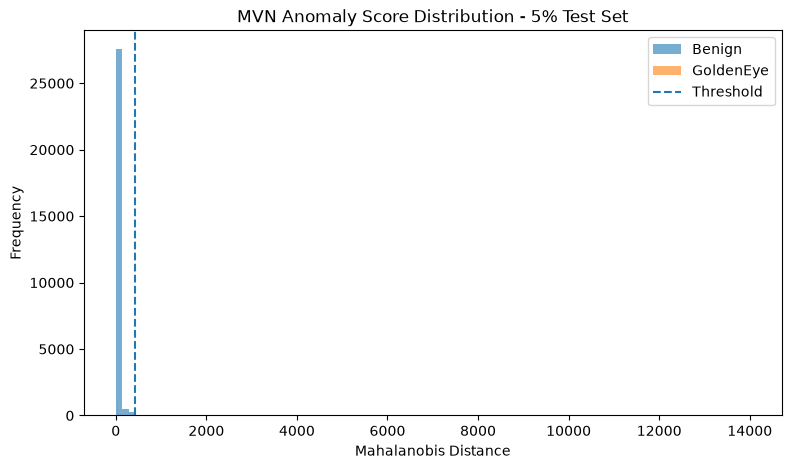

In [40]:
benign_scores = mvn_test_5_scores[
    y_test_5 == 0
]

attack_scores = mvn_test_5_scores[
    y_test_5 == 1
]

plt.figure(figsize=(9, 5))

plt.hist(
    benign_scores,
    bins=100,
    alpha=0.6,
    label="Benign"
)

plt.hist(
    attack_scores,
    bins=100,
    alpha=0.6,
    label="GoldenEye"
)

plt.axvline(
    mvn_threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Mahalanobis Distance")
plt.ylabel("Frequency")
plt.title("MVN Anomaly Score Distribution - 5% Test Set")
plt.legend()

plt.show()

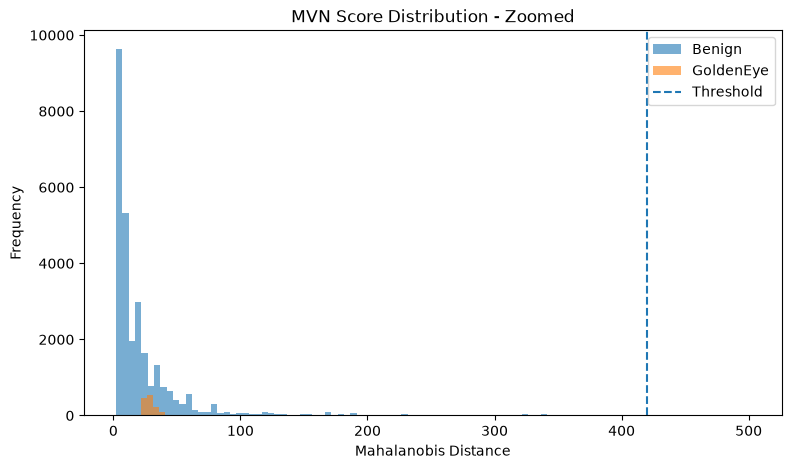

In [41]:
upper_limit = np.quantile(
    mvn_test_5_scores,
    0.995
)

plt.figure(figsize=(9, 5))

plt.hist(
    benign_scores[
        benign_scores <= upper_limit
    ],
    bins=100,
    alpha=0.6,
    label="Benign"
)

plt.hist(
    attack_scores[
        attack_scores <= upper_limit
    ],
    bins=100,
    alpha=0.6,
    label="GoldenEye"
)

plt.axvline(
    mvn_threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Mahalanobis Distance")
plt.ylabel("Frequency")
plt.title("MVN Score Distribution - Zoomed")
plt.legend()

plt.show()

## MVN Threshold Sensitivity Analysis

Several benign-calibration quantiles are examined to understand the trade-off between false positives and attack detection.

In [42]:
threshold_results = []

for target_fpr in [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05
]:

    threshold = np.quantile(
        mvn_calibration_scores,
        1 - target_fpr
    )

    pred = (
        mvn_test_5_scores > threshold
    ).astype(int)

    result = evaluate_predictions(
        "MVN",
        y_test_5,
        pred
    )

    threshold_results.append({
        "Target Calibration FPR": target_fpr,
        "Threshold": threshold,
        "Test Precision": result["Precision"],
        "Test Recall": result["Recall"],
        "Test F1": result["F1-Score"],
        "Test FPR": result["FPR"]
    })

pd.DataFrame(
    threshold_results
).round(4)

,Target Calibration FPR,Threshold,Test Precision,Test Recall,Test F1,Test FPR
0,0.001,1082.8203,0.4156,0.0213,0.0406,0.0016
1,0.005,419.8895,0.2053,0.0260,0.0462,0.0053
2,0.010,338.2139,0.1189,0.0260,0.0427,0.0101
3,0.020,187.6605,0.0725,0.0320,0.0444,0.0215
4,0.050,89.2678,0.0597,0.0613,0.0605,0.0508


### Observation

Threshold sensitivity analysis confirms that the weak MVN performance is mainly caused by poor separation between benign and GoldenEye traffic rather than by a single inappropriate threshold.

Even when the allowed false-positive rate is increased to approximately 5%, Recall reaches only 0.0613 and F1-score 0.0605. Therefore, the single multivariate Gaussian assumption is not suitable for representing the complex benign network-traffic distribution in this experiment.

## Isolation Forest

Isolation Forest detects anomalies by recursively partitioning the feature space. Observations that can be isolated using fewer random splits receive higher anomaly scores.

The model is trained only on benign traffic. A separate benign calibration set is used to determine the anomaly threshold.

In [43]:
isolation_forest = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

isolation_forest.fit(
    X_train_if
)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [44]:
if_calibration_scores = -isolation_forest.score_samples(
    X_calibration_if
)

if_test_02_scores = -isolation_forest.score_samples(
    X_test_02_if
)

if_test_1_scores = -isolation_forest.score_samples(
    X_test_1_if
)

if_test_5_scores = -isolation_forest.score_samples(
    X_test_5_if
)

### Isolation Forest Threshold

In [45]:
if_threshold = np.quantile(
    if_calibration_scores,
    THRESHOLD_QUANTILE
)

print(
    "Isolation Forest threshold:",
    if_threshold
)

Isolation Forest threshold: 0.6640869673895615


In [46]:
if_pred_02 = (
    if_test_02_scores > if_threshold
).astype(int)

if_pred_1 = (
    if_test_1_scores > if_threshold
).astype(int)

if_pred_5 = (
    if_test_5_scores > if_threshold
).astype(int)

### Isolation Forest Results

In [47]:
if_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "Isolation Forest",
            y_test_02,
            if_pred_02
        )
    },

    {
        "Test Set": "1%",
        **evaluate_predictions(
            "Isolation Forest",
            y_test_1,
            if_pred_1
        )
    },

    {
        "Test Set": "5%",
        **evaluate_predictions(
            "Isolation Forest",
            y_test_5,
            if_pred_5
        )
    }
]

if_results_df = pd.DataFrame(
    if_results
)

if_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Isolation Forest,0.9912,0.0000,0.0000,0.0000,0.0068,1.0000
1,1%,Isolation Forest,0.9833,0.0000,0.0000,0.0000,0.0068,1.0000
2,5%,Isolation Forest,0.9438,0.0053,0.0007,0.0012,0.0066,0.9993


In [48]:
score_summary(
    if_test_5_scores,
    y_test_5
).round(4)

,Group,Mean,Median,95th Percentile,99th Percentile
0,Benign,0.3947,0.3726,0.5521,0.6375
1,GoldenEye,0.4317,0.4310,0.5178,0.5992


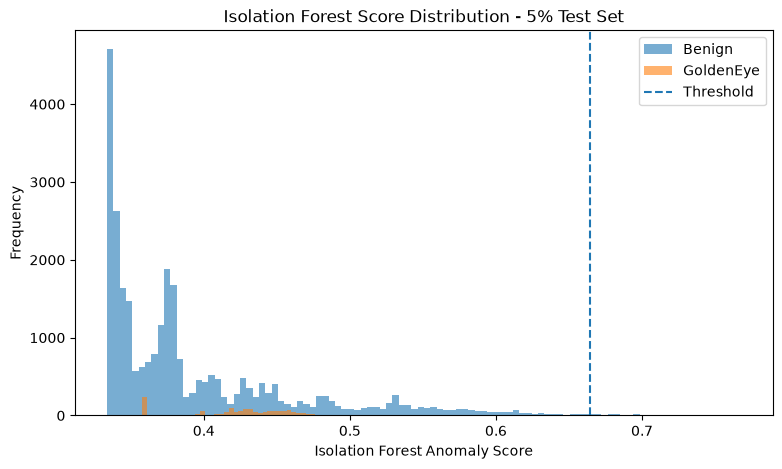

In [49]:
if_benign_scores = if_test_5_scores[
    y_test_5 == 0
]

if_attack_scores = if_test_5_scores[
    y_test_5 == 1
]

plt.figure(figsize=(9, 5))

plt.hist(
    if_benign_scores,
    bins=100,
    alpha=0.6,
    label="Benign"
)

plt.hist(
    if_attack_scores,
    bins=100,
    alpha=0.6,
    label="GoldenEye"
)

plt.axvline(
    if_threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Isolation Forest Anomaly Score")
plt.ylabel("Frequency")
plt.title(
    "Isolation Forest Score Distribution - 5% Test Set"
)

plt.legend()
plt.show()

### Observation

Isolation Forest also performs poorly under the baseline configuration. Although GoldenEye traffic has a slightly higher average anomaly score than benign traffic, the extreme upper tail of the benign score distribution is larger.

As a result, thresholding the highest anomaly scores primarily identifies rare benign flows instead of GoldenEye attacks. This leads to near-zero Recall and F1-score despite high overall Accuracy.

The result suggests substantial overlap between benign and GoldenEye traffic in the original feature space.

## One-Class SVM

One-Class SVM learns a boundary around normal observations in feature space and classifies observations outside that boundary as anomalies.

Because kernel-based One-Class SVM has high computational and memory complexity, a fixed subset of benign training samples is used while preserving the complete calibration and test sets.

In [50]:
OCSVM_TRAIN_SIZE = 20_000

rng = np.random.default_rng(RANDOM_STATE)

ocsvm_indices = rng.choice(
    len(X_train_standard),
    size=OCSVM_TRAIN_SIZE,
    replace=False
)

X_train_ocsvm = X_train_standard[
    ocsvm_indices
]

print(
    "OCSVM training shape:",
    X_train_ocsvm.shape
)

OCSVM training shape: (20000, 68)


In [51]:
ocsvm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.01
)

ocsvm_model.fit(
    X_train_ocsvm
)

,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.01
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


In [52]:
ocsvm_calibration_scores = -ocsvm_model.decision_function(
    X_calibration_standard
)

ocsvm_test_02_scores = -ocsvm_model.decision_function(
    X_test_02_standard
)

ocsvm_test_1_scores = -ocsvm_model.decision_function(
    X_test_1_standard
)

ocsvm_test_5_scores = -ocsvm_model.decision_function(
    X_test_5_standard
)

### One-Class SVM Threshold

In [53]:
ocsvm_threshold = np.quantile(
    ocsvm_calibration_scores,
    THRESHOLD_QUANTILE
)

print(
    "One-Class SVM threshold:",
    ocsvm_threshold
)

One-Class SVM threshold: 0.40776500604035887


In [54]:
ocsvm_pred_02 = (
    ocsvm_test_02_scores > ocsvm_threshold
).astype(int)

ocsvm_pred_1 = (
    ocsvm_test_1_scores > ocsvm_threshold
).astype(int)

ocsvm_pred_5 = (
    ocsvm_test_5_scores > ocsvm_threshold
).astype(int)

### One-Class SVM Results

In [55]:
ocsvm_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "One-Class SVM",
            y_test_02,
            ocsvm_pred_02
        )
    },

    {
        "Test Set": "1%",
        **evaluate_predictions(
            "One-Class SVM",
            y_test_1,
            ocsvm_pred_1
        )
    },

    {
        "Test Set": "5%",
        **evaluate_predictions(
            "One-Class SVM",
            y_test_5,
            ocsvm_pred_5
        )
    }
]

ocsvm_results_df = pd.DataFrame(
    ocsvm_results
)

ocsvm_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,One-Class SVM,0.9916,0.0000,0.0000,0.0000,0.0064,1.0000
1,1%,One-Class SVM,0.9838,0.0256,0.0167,0.0202,0.0064,0.9833
2,5%,One-Class SVM,0.9456,0.2121,0.0327,0.0566,0.0064,0.9673


In [56]:
score_summary(
    ocsvm_test_5_scores,
    y_test_5
).round(4)

,Group,Mean,Median,95th Percentile,99th Percentile
0,Benign,-0.9957,-1.1001,-0.0723,0.0497
1,GoldenEye,-1.3372,-1.5690,-0.2259,3.3194


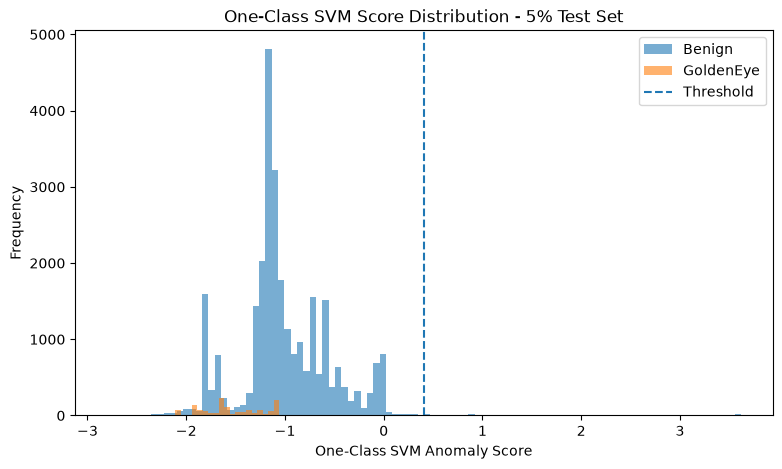

In [57]:
ocsvm_benign_scores = ocsvm_test_5_scores[
    y_test_5 == 0
]

ocsvm_attack_scores = ocsvm_test_5_scores[
    y_test_5 == 1
]

plt.figure(figsize=(9, 5))

plt.hist(
    ocsvm_benign_scores,
    bins=100,
    alpha=0.6,
    label="Benign"
)

plt.hist(
    ocsvm_attack_scores,
    bins=100,
    alpha=0.6,
    label="GoldenEye"
)

plt.axvline(
    ocsvm_threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("One-Class SVM Anomaly Score")
plt.ylabel("Frequency")
plt.title(
    "One-Class SVM Score Distribution - 5% Test Set"
)

plt.legend()
plt.show()

### Observation

The baseline One-Class SVM detects only a small fraction of GoldenEye attacks. At the 5% anomaly level, the model achieves an F1-score of 0.0566 with Recall of 0.0327.

The anomaly-score distribution shows that most GoldenEye observations overlap with the benign distribution, although a small subset receives very high anomaly scores. This indicates that the baseline RBF decision boundary identifies only the most extreme attack samples.

Hyperparameters such as `nu` and `gamma` may substantially influence this behaviour and will therefore be considered during later optimization.

## Autoencoder

The Autoencoder is trained only on benign traffic to reconstruct normal network behaviour.

Samples producing large reconstruction errors are considered anomalous. The anomaly threshold is determined using the separate benign calibration set.

In [58]:
input_dim = X_train_minmax.shape[1]

autoencoder = keras.Sequential([
    layers.Input(shape=(input_dim,)),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        16,
        activation="relu",
        name="latent_space"
    ),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(
        input_dim,
        activation="linear"
    )
])

autoencoder.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 68)             │         4,420 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,100 (55.08 KB)

 Trainable params: 14,100 (55.08 KB)

 Non-trainable params: 0 (0.00 B)

### Autoencoder Training

Early stopping is used to prevent overfitting. A fraction of the benign training data is used internally for validation, while the separate calibration set remains untouched for threshold estimation.

In [59]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train_minmax,
    X_train_minmax,

    epochs=50,
    batch_size=512,

    validation_split=0.1,

    callbacks=[
        early_stopping
    ],

    verbose=1
)

Epoch 1/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0101 - val_loss: 0.0024
Epoch 2/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0013 - val_loss: 7.9628e-04
Epoch 3/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.5423e-04 - val_loss: 5.2661e-04
Epoch 4/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.7880e-04 - val_loss: 4.0126e-04
Epoch 5/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.7650e-04 - val_loss: 3.1312e-04
Epoch 6/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.0627e-04 - val_loss: 2.6440e-04
Epoch 7/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.6436e-04 - val_loss: 2.3055e-04
Epoch 8/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.3220e-04 - val_loss: 2.0294e-04
Epoch 9/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.0602e-04 - val_loss: 1.8255e-04
Epoch 10/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.8591e-04 - val_loss: 1.6770e-04
Epoch 11/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.7129e-04

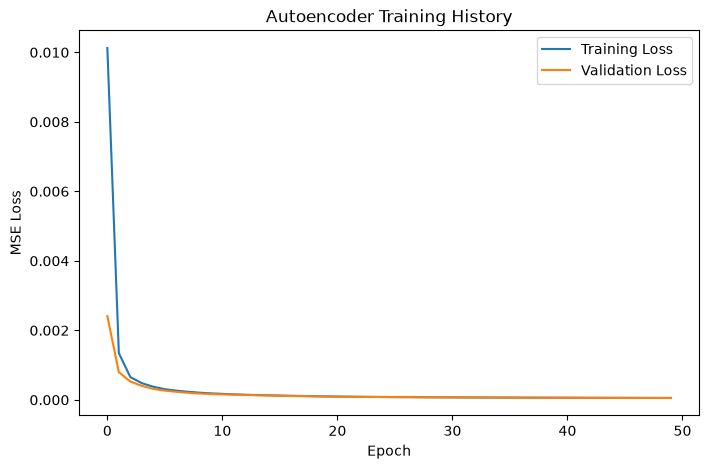

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training History")

plt.legend()
plt.show()

### Reconstruction Error

The mean squared reconstruction error of each network flow is used as its anomaly score. Larger reconstruction error indicates greater deviation from learned benign behaviour.

In [61]:
def reconstruction_error(
    model,
    X
):

    reconstructed = model.predict(
        X,
        batch_size=1024,
        verbose=0
    )

    return np.mean(
        np.square(
            X - reconstructed
        ),
        axis=1
    )

In [62]:
ae_calibration_scores = reconstruction_error(
    autoencoder,
    X_calibration_minmax
)

ae_test_02_scores = reconstruction_error(
    autoencoder,
    X_test_02_minmax
)

ae_test_1_scores = reconstruction_error(
    autoencoder,
    X_test_1_minmax
)

ae_test_5_scores = reconstruction_error(
    autoencoder,
    X_test_5_minmax
)

### Autoencoder Threshold

In [63]:
ae_threshold = np.quantile(
    ae_calibration_scores,
    THRESHOLD_QUANTILE
)

print(
    "Autoencoder threshold:",
    ae_threshold
)

Autoencoder threshold: 0.0014103959751541801


In [64]:
ae_pred_02 = (
    ae_test_02_scores
    > ae_threshold
).astype(int)

ae_pred_1 = (
    ae_test_1_scores
    > ae_threshold
).astype(int)

ae_pred_5 = (
    ae_test_5_scores
    > ae_threshold
).astype(int)

### Autoencoder Results

In [65]:
ae_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "Autoencoder",
            y_test_02,
            ae_pred_02
        )
    },

    {
        "Test Set": "1%",
        **evaluate_predictions(
            "Autoencoder",
            y_test_1,
            ae_pred_1
        )
    },

    {
        "Test Set": "5%",
        **evaluate_predictions(
            "Autoencoder",
            y_test_5,
            ae_pred_5
        )
    }
]

ae_results_df = pd.DataFrame(
    ae_results
)

ae_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Autoencoder,0.9923,0.0479,0.1500,0.0726,0.006,0.8500
1,1%,Autoencoder,0.9860,0.2447,0.1933,0.2160,0.006,0.8067
2,5%,Autoencoder,0.9535,0.6183,0.1847,0.2844,0.006,0.8153


In [66]:
score_summary(
    ae_test_5_scores,
    y_test_5
).round(6)

,Group,Mean,Median,95th Percentile,99th Percentile
0,Benign,0.000053,0.000006,0.000148,0.000824
1,GoldenEye,0.001223,0.000735,0.002198,0.013251


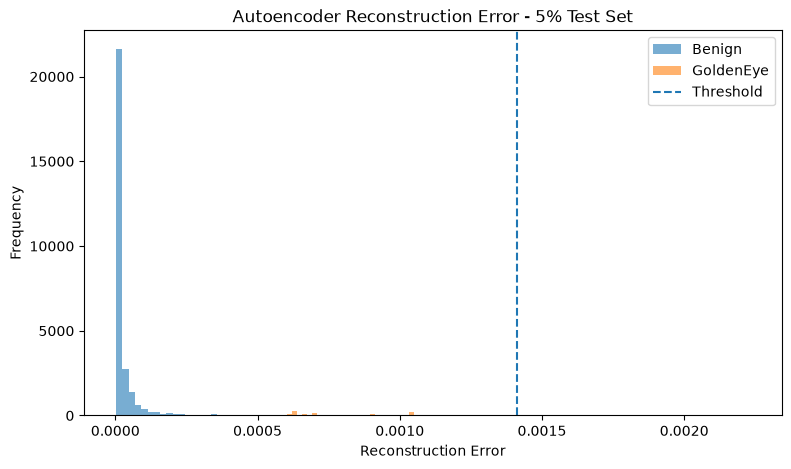

In [67]:
ae_benign_scores = ae_test_5_scores[
    y_test_5 == 0
]

ae_attack_scores = ae_test_5_scores[
    y_test_5 == 1
]

upper_limit = np.quantile(
    ae_test_5_scores,
    0.995
)

plt.figure(figsize=(9, 5))

plt.hist(
    ae_benign_scores[
        ae_benign_scores <= upper_limit
    ],
    bins=100,
    alpha=0.6,
    label="Benign"
)

plt.hist(
    ae_attack_scores[
        ae_attack_scores <= upper_limit
    ],
    bins=100,
    alpha=0.6,
    label="GoldenEye"
)

plt.axvline(
    ae_threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")

plt.title(
    "Autoencoder Reconstruction Error - 5% Test Set"
)

plt.legend()
plt.show()

### Observation

The Autoencoder substantially outperforms the statistical and classical unsupervised baselines.

At the 5% anomaly rate, the Autoencoder achieves an F1-score of 0.2844 with Precision of 0.6183, while MVN, Isolation Forest and One-Class SVM remain below 0.06 F1.

The reconstruction-error distribution shows clearer separation between benign and GoldenEye traffic. GoldenEye samples have substantially larger reconstruction errors, indicating that the neural network learns benign traffic patterns that are more difficult to reproduce for attack traffic.

However, Recall remains relatively low, suggesting that feature selection and hyperparameter optimization may further improve detection.

## Experiment 1 - Baseline Model Comparison

In [68]:
experiment_1_results = pd.concat(
    [
        mvn_results_df,
        if_results_df,
        ocsvm_results_df,
        ae_results_df
    ],
    ignore_index=True
)

experiment_1_results.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,MVN,0.9927,0.0000,0.0000,0.0000,0.0053,1.0000
1,1%,MVN,0.9848,0.0245,0.0133,0.0173,0.0054,0.9867
2,5%,MVN,0.9463,0.2053,0.0260,0.0462,0.0053,0.9740
3,0.2%,Isolation Forest,0.9912,0.0000,0.0000,0.0000,0.0068,1.0000
4,1%,Isolation Forest,0.9833,0.0000,0.0000,0.0000,0.0068,1.0000
5,5%,Isolation Forest,0.9438,0.0053,0.0007,0.0012,0.0066,0.9993
6,0.2%,One-Class SVM,0.9916,0.0000,0.0000,0.0000,0.0064,1.0000
7,1%,One-Class SVM,0.9838,0.0256,0.0167,0.0202,0.0064,0.9833
8,5%,One-Class SVM,0.9456,0.2121,0.0327,0.0566,0.0064,0.9673
9,0.2%,Autoencoder,0.9923,0.0479,0.1500,0.0726,0.0060,0.8500


In [69]:
experiment_1_5 = (
    experiment_1_results[
        experiment_1_results["Test Set"] == "5%"
    ]
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

experiment_1_5.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,5%,Autoencoder,0.9535,0.6183,0.1847,0.2844,0.0060,0.8153
1,5%,One-Class SVM,0.9456,0.2121,0.0327,0.0566,0.0064,0.9673
2,5%,MVN,0.9463,0.2053,0.0260,0.0462,0.0053,0.9740
3,5%,Isolation Forest,0.9438,0.0053,0.0007,0.0012,0.0066,0.9993


### Experiment 1 Conclusion

Among the four baseline unsupervised models, the Autoencoder provides the strongest anomaly-detection performance. Classical models struggle because benign and GoldenEye traffic overlap considerably in the original high-dimensional feature space.

The next experiment investigates whether removing redundant features improves anomaly separation.

# Experiment 2 - Selected Features, No Hyperparameter Optimization

Highly correlated features are removed using only benign training traffic.

Removing redundant features can reduce multicollinearity, simplify the feature space and improve the ability of anomaly detection models to identify meaningful deviations from normal behaviour.

In [70]:
correlation_matrix = (
    X_train_clean
    .corr()
    .abs()
)

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(
            correlation_matrix.shape
        ),
        k=1
    ).astype(bool)
)

correlated_features = [
    column
    for column in upper_triangle.columns
    if any(
        upper_triangle[column] > 0.95
    )
]

print(
    "Number of features before correlation filtering:",
    X_train_clean.shape[1]
)

print(
    "Number of highly correlated features removed:",
    len(correlated_features)
)

print(
    "Remaining features:",
    X_train_clean.shape[1]
    - len(correlated_features)
)

Number of features before correlation filtering: 68
Number of highly correlated features removed: 25
Remaining features: 43


In [71]:
selected_features = [
    column
    for column in X_train_clean.columns
    if column not in correlated_features
]

X_train_selected = X_train_clean[
    selected_features
].copy()

X_calibration_selected = X_calibration_clean[
    selected_features
].copy()

X_test_02_selected = X_test_02_clean[
    selected_features
].copy()

X_test_1_selected = X_test_1_clean[
    selected_features
].copy()

X_test_5_selected = X_test_5_clean[
    selected_features
].copy()

print(
    "Selected feature count:",
    len(selected_features)
)

Selected feature count: 43


In [72]:
standard_scaler_selected = StandardScaler()

X_train_standard_selected = (
    standard_scaler_selected.fit_transform(
        X_train_selected
    )
)

X_calibration_standard_selected = (
    standard_scaler_selected.transform(
        X_calibration_selected
    )
)

X_test_02_standard_selected = (
    standard_scaler_selected.transform(
        X_test_02_selected
    )
)

X_test_1_standard_selected = (
    standard_scaler_selected.transform(
        X_test_1_selected
    )
)

X_test_5_standard_selected = (
    standard_scaler_selected.transform(
        X_test_5_selected
    )
)

In [73]:
minmax_scaler_selected = MinMaxScaler()

X_train_minmax_selected = (
    minmax_scaler_selected.fit_transform(
        X_train_selected
    )
)

X_calibration_minmax_selected = (
    minmax_scaler_selected.transform(
        X_calibration_selected
    )
)

X_test_02_minmax_selected = (
    minmax_scaler_selected.transform(
        X_test_02_selected
    )
)

X_test_1_minmax_selected = (
    minmax_scaler_selected.transform(
        X_test_1_selected
    )
)

X_test_5_minmax_selected = (
    minmax_scaler_selected.transform(
        X_test_5_selected
    )
)

In [74]:
X_train_if_selected = X_train_selected.to_numpy()

X_calibration_if_selected = (
    X_calibration_selected.to_numpy()
)

X_test_02_if_selected = (
    X_test_02_selected.to_numpy()
)

X_test_1_if_selected = (
    X_test_1_selected.to_numpy()
)

X_test_5_if_selected = (
    X_test_5_selected.to_numpy()
)

### Observation

Correlation filtering removed 25 highly redundant features, reducing the feature space from 68 to 43 features. This simplifies the representation while retaining less redundant information from benign traffic.

## MVN with Selected Features

In [76]:
mvn_selected = LedoitWolf()

mvn_selected.fit(
    X_train_standard_selected
)

,"store_precision store_precision: bool, default=TrueSpecify if the estimated precision is stored.",True
,"assume_centered assume_centered: bool, default=FalseIf True, data will not be centered before computation.Useful when working with data whose mean is almost, but not exactlyzero.If False (default), data will be centered before computation.",False
,"block_size block_size: int, default=1000Size of blocks into which the covariance matrix will be splitduring its Ledoit-Wolf estimation. This is purely a memoryoptimization and does not affect results.",1000
Name,Type,Value
"covariance_ covariance_: ndarray of shape (n_features, n_features)Estimated covariance matrix.","ndarray[float64](43, 43)","[[ 1. ,-0.28,-0.15,...,-0.04,-0.1 ,-0.02], [-0.28, 1. ,-0.32,...,-0.09,-0.25,-0.06], [-0.15,-0.32, 1. ,..., 0.27, 0.7 , 0.18], ..., [-0.04,-0.09, 0.27,..., 1. , 0.17, 0.16], [-0.1 ,-0.25, 0.7 ,..., 0.17, 1. , 0.18], [-0.02,-0.06, 0.18,..., 0.16, 0.18, 1. ]]"
"location_ location_: ndarray of shape (n_features,)Estimated location, i.e. the estimated mean.","ndarray[float64](43,)","[ 0.,-0., 0.,..., 0.,-0.,-0.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,43
"precision_ precision_: ndarray of shape (n_features, n_features)Estimated pseudo inverse matrix.(stored only if store_precision is True)","ndarray[float64](43, 43)","[[ 2.18, 0.27, 0.05,...,-0.01,-0.24,-0.02], [ 0.27, 6.49, 1.52,...,-0.01, 1.4 , 0.12], [ 0.05, 1.52, 9.85,...,-0.42,-1.12,-0.13], ..., [-0.01,-0.01,-0.42,..., 8.23, 0.16, 0.08], [-0.24, 1.4 ,-1.12,..., 0.16, 4.67, 0.33], [-0.02, 0.12,-0.13,..., 0.08, 0.33, 1.21]]"
"shrinkage_ shrinkage_: floatCoefficient in the convex combination used for the computationof the shrunk estimate. Range is [0, 1].",float64,0.04663


In [77]:
mvn_selected_calibration_scores = (
    mvn_selected.mahalanobis(
        X_calibration_standard_selected
    )
)

mvn_selected_test_02_scores = (
    mvn_selected.mahalanobis(
        X_test_02_standard_selected
    )
)

mvn_selected_test_1_scores = (
    mvn_selected.mahalanobis(
        X_test_1_standard_selected
    )
)

mvn_selected_test_5_scores = (
    mvn_selected.mahalanobis(
        X_test_5_standard_selected
    )
)

### Threshold and Evaluation

In [78]:
mvn_selected_threshold = np.quantile(
    mvn_selected_calibration_scores,
    THRESHOLD_QUANTILE
)

mvn_selected_pred_02 = (
    mvn_selected_test_02_scores
    > mvn_selected_threshold
).astype(int)

mvn_selected_pred_1 = (
    mvn_selected_test_1_scores
    > mvn_selected_threshold
).astype(int)

mvn_selected_pred_5 = (
    mvn_selected_test_5_scores
    > mvn_selected_threshold
).astype(int)

In [79]:
mvn_selected_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "MVN - Selected",
            y_test_02,
            mvn_selected_pred_02
        )
    },
    {
        "Test Set": "1%",
        **evaluate_predictions(
            "MVN - Selected",
            y_test_1,
            mvn_selected_pred_1
        )
    },
    {
        "Test Set": "5%",
        **evaluate_predictions(
            "MVN - Selected",
            y_test_5,
            mvn_selected_pred_5
        )
    }
]

mvn_selected_results_df = pd.DataFrame(
    mvn_selected_results
)

mvn_selected_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,MVN - Selected,0.9917,0.0000,0.0000,0.0000,0.0063,1.0000
1,1%,MVN - Selected,0.9839,0.0208,0.0133,0.0163,0.0063,0.9867
2,5%,MVN - Selected,0.9454,0.1806,0.0260,0.0455,0.0062,0.9740


### Observation

Correlation-based feature reduction does not improve MVN performance. The 5% anomaly F1-score remains approximately 0.046, indicating that the main limitation is the Gaussian distribution assumption rather than redundant features.

## Isolation Forest with Selected Features

In [80]:
isolation_forest_selected = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

isolation_forest_selected.fit(
    X_train_if_selected
)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [81]:
if_selected_calibration_scores = -isolation_forest_selected.score_samples(
    X_calibration_if_selected
)

if_selected_test_02_scores = -isolation_forest_selected.score_samples(
    X_test_02_if_selected
)

if_selected_test_1_scores = -isolation_forest_selected.score_samples(
    X_test_1_if_selected
)

if_selected_test_5_scores = -isolation_forest_selected.score_samples(
    X_test_5_if_selected
)

### Threshold and Evaluation

In [82]:
if_selected_threshold = np.quantile(
    if_selected_calibration_scores,
    THRESHOLD_QUANTILE
)

if_selected_pred_02 = (
    if_selected_test_02_scores
    > if_selected_threshold
).astype(int)

if_selected_pred_1 = (
    if_selected_test_1_scores
    > if_selected_threshold
).astype(int)

if_selected_pred_5 = (
    if_selected_test_5_scores
    > if_selected_threshold
).astype(int)

In [83]:
if_selected_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "Isolation Forest - Selected",
            y_test_02,
            if_selected_pred_02
        )
    },
    {
        "Test Set": "1%",
        **evaluate_predictions(
            "Isolation Forest - Selected",
            y_test_1,
            if_selected_pred_1
        )
    },
    {
        "Test Set": "5%",
        **evaluate_predictions(
            "Isolation Forest - Selected",
            y_test_5,
            if_selected_pred_5
        )
    }
]

if_selected_results_df = pd.DataFrame(
    if_selected_results
)

if_selected_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Isolation Forest - Selected,0.9910,0.0000,0.0000,0.0000,0.0070,1.0000
1,1%,Isolation Forest - Selected,0.9832,0.0096,0.0067,0.0079,0.0070,0.9933
2,5%,Isolation Forest - Selected,0.9437,0.0437,0.0060,0.0106,0.0069,0.9940


### Observation

Correlation filtering slightly improves Isolation Forest performance, but the model still detects very few GoldenEye attacks. The 5% anomaly F1-score increases to 0.0106, while Recall remains extremely low at 0.0060.

## One-Class SVM with Selected Features

In [84]:
rng = np.random.default_rng(
    RANDOM_STATE
)

ocsvm_selected_indices = rng.choice(
    len(X_train_standard_selected),
    size=OCSVM_TRAIN_SIZE,
    replace=False
)

X_train_ocsvm_selected = (
    X_train_standard_selected[
        ocsvm_selected_indices
    ]
)

print(
    "OCSVM selected-feature training shape:",
    X_train_ocsvm_selected.shape
)

OCSVM selected-feature training shape: (20000, 43)


In [85]:
ocsvm_selected = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.01
)

ocsvm_selected.fit(
    X_train_ocsvm_selected
)

,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.01
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


In [86]:
ocsvm_selected_calibration_scores = -ocsvm_selected.decision_function(
    X_calibration_standard_selected
)

ocsvm_selected_test_02_scores = -ocsvm_selected.decision_function(
    X_test_02_standard_selected
)

ocsvm_selected_test_1_scores = -ocsvm_selected.decision_function(
    X_test_1_standard_selected
)

ocsvm_selected_test_5_scores = -ocsvm_selected.decision_function(
    X_test_5_standard_selected
)

### Threshold and Evaluation

In [87]:
ocsvm_selected_threshold = np.quantile(
    ocsvm_selected_calibration_scores,
    THRESHOLD_QUANTILE
)

ocsvm_selected_pred_02 = (
    ocsvm_selected_test_02_scores
    > ocsvm_selected_threshold
).astype(int)

ocsvm_selected_pred_1 = (
    ocsvm_selected_test_1_scores
    > ocsvm_selected_threshold
).astype(int)

ocsvm_selected_pred_5 = (
    ocsvm_selected_test_5_scores
    > ocsvm_selected_threshold
).astype(int)

In [88]:
ocsvm_selected_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "One-Class SVM - Selected",
            y_test_02,
            ocsvm_selected_pred_02
        )
    },
    {
        "Test Set": "1%",
        **evaluate_predictions(
            "One-Class SVM - Selected",
            y_test_1,
            ocsvm_selected_pred_1
        )
    },
    {
        "Test Set": "5%",
        **evaluate_predictions(
            "One-Class SVM - Selected",
            y_test_5,
            ocsvm_selected_pred_5
        )
    }
]

ocsvm_selected_results_df = pd.DataFrame(
    ocsvm_selected_results
)

ocsvm_selected_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,One-Class SVM - Selected,0.9916,0.0000,0.0000,0.0000,0.0064,1.0000
1,1%,One-Class SVM - Selected,0.9838,0.0254,0.0167,0.0201,0.0065,0.9833
2,5%,One-Class SVM - Selected,0.9454,0.2035,0.0313,0.0543,0.0065,0.9687


### Observation

Correlation-based feature reduction does not improve One-Class SVM performance. The 5% anomaly F1-score changes only slightly from 0.0566 to 0.0543, indicating that redundant features are not the main limitation for this model.

## Autoencoder with Selected Features

In [89]:
input_dim_selected = X_train_minmax_selected.shape[1]

autoencoder_selected = keras.Sequential([
    layers.Input(shape=(input_dim_selected,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu", name="latent_space"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(input_dim_selected, activation="linear")
])

autoencoder_selected.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

autoencoder_selected.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 43)             │         2,795 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,875 (42.48 KB)

 Trainable params: 10,875 (42.48 KB)

 Non-trainable params: 0 (0.00 B)

### Train Selected-Feature Autoencoder

In [90]:
early_stopping_selected = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_selected = autoencoder_selected.fit(
    X_train_minmax_selected,
    X_train_minmax_selected,
    epochs=50,
    batch_size=512,
    validation_split=0.1,
    callbacks=[early_stopping_selected],
    verbose=1
)

Epoch 1/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0118 - val_loss: 0.0022
Epoch 2/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0014 - val_loss: 8.9594e-04
Epoch 3/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.8490e-04 - val_loss: 5.3726e-04
Epoch 4/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.7115e-04 - val_loss: 4.2554e-04
Epoch 5/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.8226e-04 - val_loss: 3.4454e-04
Epoch 6/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.0764e-04 - val_loss: 2.6992e-04
Epoch 7/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.4656e-04 - val_loss: 2.2134e-04
Epoch 8/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.0359e-04 - val_loss: 1.8358e-04
Epoch 9/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.7279e-04 - val_loss: 1.6216e-04
Epoch 10/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.5151e-04 - val_loss: 1.4368e-04
Epoch 11/50
176/176 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.3433e-04

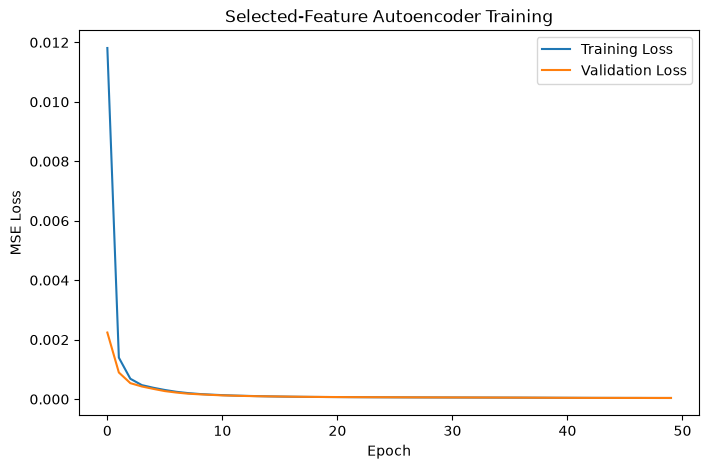

In [91]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_selected.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_selected.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Selected-Feature Autoencoder Training")

plt.legend()
plt.show()

### Reconstruction Error and Threshold

In [92]:
ae_selected_calibration_scores = reconstruction_error(
    autoencoder_selected,
    X_calibration_minmax_selected
)

ae_selected_test_02_scores = reconstruction_error(
    autoencoder_selected,
    X_test_02_minmax_selected
)

ae_selected_test_1_scores = reconstruction_error(
    autoencoder_selected,
    X_test_1_minmax_selected
)

ae_selected_test_5_scores = reconstruction_error(
    autoencoder_selected,
    X_test_5_minmax_selected
)

In [93]:
ae_selected_threshold = np.quantile(
    ae_selected_calibration_scores,
    THRESHOLD_QUANTILE
)

print(
    "Selected Autoencoder threshold:",
    ae_selected_threshold
)

Selected Autoencoder threshold: 0.0009397585366290171


In [94]:
ae_selected_pred_02 = (
    ae_selected_test_02_scores
    > ae_selected_threshold
).astype(int)

ae_selected_pred_1 = (
    ae_selected_test_1_scores
    > ae_selected_threshold
).astype(int)

ae_selected_pred_5 = (
    ae_selected_test_5_scores
    > ae_selected_threshold
).astype(int)

### Selected-Feature Autoencoder Results

In [95]:
ae_selected_results = [
    {
        "Test Set": "0.2%",
        **evaluate_predictions(
            "Autoencoder - Selected",
            y_test_02,
            ae_selected_pred_02
        )
    },
    {
        "Test Set": "1%",
        **evaluate_predictions(
            "Autoencoder - Selected",
            y_test_1,
            ae_selected_pred_1
        )
    },
    {
        "Test Set": "5%",
        **evaluate_predictions(
            "Autoencoder - Selected",
            y_test_5,
            ae_selected_pred_5
        )
    }
]

ae_selected_results_df = pd.DataFrame(
    ae_selected_results
)

ae_selected_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Autoencoder - Selected,0.9928,0.0984,0.3167,0.1502,0.0058,0.6833
1,1%,Autoencoder - Selected,0.9878,0.3799,0.3533,0.3661,0.0058,0.6467
2,5%,Autoencoder - Selected,0.9624,0.7650,0.3580,0.4877,0.0058,0.6420


In [96]:
score_summary(
    ae_selected_test_5_scores,
    y_test_5
).round(6)

,Group,Mean,Median,95th Percentile,99th Percentile
0,Benign,0.000038,0.000007,0.000083,0.000639
1,GoldenEye,0.000851,0.000683,0.002294,0.002908


### Observation

Correlation-based feature reduction substantially improves the Autoencoder. At the 5% anomaly rate, F1-score increases from 0.2844 to 0.4877, while Recall improves from 0.1847 to 0.3580.

This suggests that removing highly redundant features helps the Autoencoder learn a more informative representation of benign network behaviour.

## Experiment 2 - Selected Feature Comparison

In [97]:
experiment_2_results = pd.concat(
    [
        mvn_selected_results_df,
        if_selected_results_df,
        ocsvm_selected_results_df,
        ae_selected_results_df
    ],
    ignore_index=True
)

experiment_2_results.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,MVN - Selected,0.9917,0.0000,0.0000,0.0000,0.0063,1.0000
1,1%,MVN - Selected,0.9839,0.0208,0.0133,0.0163,0.0063,0.9867
2,5%,MVN - Selected,0.9454,0.1806,0.0260,0.0455,0.0062,0.9740
3,0.2%,Isolation Forest - Selected,0.9910,0.0000,0.0000,0.0000,0.0070,1.0000
4,1%,Isolation Forest - Selected,0.9832,0.0096,0.0067,0.0079,0.0070,0.9933
5,5%,Isolation Forest - Selected,0.9437,0.0437,0.0060,0.0106,0.0069,0.9940
6,0.2%,One-Class SVM - Selected,0.9916,0.0000,0.0000,0.0000,0.0064,1.0000
7,1%,One-Class SVM - Selected,0.9838,0.0254,0.0167,0.0201,0.0065,0.9833
8,5%,One-Class SVM - Selected,0.9454,0.2035,0.0313,0.0543,0.0065,0.9687
9,0.2%,Autoencoder - Selected,0.9928,0.0984,0.3167,0.1502,0.0058,0.6833


In [98]:
experiment_2_5 = (
    experiment_2_results[
        experiment_2_results["Test Set"] == "5%"
    ]
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

experiment_2_5.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,5%,Autoencoder - Selected,0.9624,0.7650,0.3580,0.4877,0.0058,0.6420
1,5%,One-Class SVM - Selected,0.9454,0.2035,0.0313,0.0543,0.0065,0.9687
2,5%,MVN - Selected,0.9454,0.1806,0.0260,0.0455,0.0062,0.9740
3,5%,Isolation Forest - Selected,0.9437,0.0437,0.0060,0.0106,0.0069,0.9940


### Experiment 2 Conclusion

The Autoencoder benefits strongly from correlation-based feature reduction and remains the best-performing unsupervised model. MVN and One-Class SVM show little change, while Isolation Forest improves only slightly.

# Experiment 3 - All Features with Hyperparameter Optimization

Optuna is used to optimize model hyperparameters.

To prevent test leakage, hyperparameter selection is performed on separate development datasets. The final 0.2%, 1%, and 5% test sets remain untouched during optimization.

In [99]:
HPO_TEST_SIZE = 10_000

HPO_ATTACK_02 = 20
HPO_ATTACK_1 = 100
HPO_ATTACK_5 = 500

hpo_attack_pool = attack_shuffled.iloc[
    1500:
].reset_index(drop=True)

hpo_benign_pool = benign_test_shuffled.iloc[
    30_000:
].reset_index(drop=True)

print(
    "Available HPO attacks:",
    len(hpo_attack_pool)
)

print(
    "Available HPO benign:",
    len(hpo_benign_pool)
)

Available HPO attacks: 39955
Available HPO benign: 844414


## Construct HPO Development Sets

Three development sets are created at the same anomaly prevalences used for final evaluation. These datasets are used only for hyperparameter selection and remain completely separate from the final test sets.

In [100]:
hpo_attack_02 = hpo_attack_pool.iloc[
    :HPO_ATTACK_02
]

hpo_attack_1 = hpo_attack_pool.iloc[
    :HPO_ATTACK_1
]

hpo_attack_5 = hpo_attack_pool.iloc[
    :HPO_ATTACK_5
]

hpo_benign_02 = hpo_benign_pool.iloc[
    :HPO_TEST_SIZE - HPO_ATTACK_02
]

hpo_benign_1 = hpo_benign_pool.iloc[
    :HPO_TEST_SIZE - HPO_ATTACK_1
]

hpo_benign_5 = hpo_benign_pool.iloc[
    :HPO_TEST_SIZE - HPO_ATTACK_5
]

In [101]:
X_hpo_02, y_hpo_02 = create_test_set(
    hpo_benign_02,
    hpo_attack_02,
    RANDOM_STATE + 10
)

X_hpo_1, y_hpo_1 = create_test_set(
    hpo_benign_1,
    hpo_attack_1,
    RANDOM_STATE + 11
)

X_hpo_5, y_hpo_5 = create_test_set(
    hpo_benign_5,
    hpo_attack_5,
    RANDOM_STATE + 12
)

In [102]:
X_hpo_02_clean = (
    X_hpo_02
    .fillna(train_medians)
    .drop(columns=constant_features)
)

X_hpo_1_clean = (
    X_hpo_1
    .fillna(train_medians)
    .drop(columns=constant_features)
)

X_hpo_5_clean = (
    X_hpo_5
    .fillna(train_medians)
    .drop(columns=constant_features)
)

In [103]:
X_hpo_02_standard = standard_scaler.transform(
    X_hpo_02_clean
)

X_hpo_1_standard = standard_scaler.transform(
    X_hpo_1_clean
)

X_hpo_5_standard = standard_scaler.transform(
    X_hpo_5_clean
)

X_hpo_02_minmax = minmax_scaler.transform(
    X_hpo_02_clean
)

X_hpo_1_minmax = minmax_scaler.transform(
    X_hpo_1_clean
)

X_hpo_5_minmax = minmax_scaler.transform(
    X_hpo_5_clean
)

X_hpo_02_if = X_hpo_02_clean.to_numpy()
X_hpo_1_if = X_hpo_1_clean.to_numpy()
X_hpo_5_if = X_hpo_5_clean.to_numpy()

In [104]:
for name, y in {
    "HPO 0.2%": y_hpo_02,
    "HPO 1%": y_hpo_1,
    "HPO 5%": y_hpo_5
}.items():

    print(
        name,
        "| Total:", len(y),
        "| Attacks:", y.sum(),
        "| Rate:",
        round(y.mean() * 100, 2),
        "%"
    )

HPO 0.2% | Total: 10000 | Attacks: 20 | Rate: 0.2 %
HPO 1% | Total: 10000 | Attacks: 100 | Rate: 1.0 %
HPO 5% | Total: 10000 | Attacks: 500 | Rate: 5.0 %


### Observation

Separate development datasets were created for hyperparameter optimization. None of these samples overlap with the final evaluation datasets, preventing hyperparameter selection from leaking information from the final test sets.

## Optuna - Isolation Forest

Isolation Forest hyperparameters and the calibration threshold are optimized using the separate development datasets.

The objective is the mean F1-score across 0.2%, 1%, and 5% anomaly rates so that optimization is not biased toward a single anomaly prevalence.

In [105]:
optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

def objective_if(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        150,
        500
    )

    max_samples = trial.suggest_float(
        "max_samples",
        0.4,
        1.0
    )

    max_features = trial.suggest_float(
        "max_features",
        0.5,
        1.0
    )

    bootstrap = trial.suggest_categorical(
        "bootstrap",
        [False, True]
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.05,
        log=True
    )

    model = IsolationForest(
        n_estimators=n_estimators,
        max_samples=max_samples,
        max_features=max_features,
        bootstrap=bootstrap,
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(
        X_train_if
    )

    calibration_scores = -model.score_samples(
        X_calibration_if
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_hpo, y_hpo in [
        (X_hpo_02_if, y_hpo_02),
        (X_hpo_1_if, y_hpo_1),
        (X_hpo_5_if, y_hpo_5)
    ]:

        scores = -model.score_samples(
            X_hpo
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_hpo,
                predictions,
                zero_division=0
            )
        )

    return np.mean(
        f1_scores
    )

### Run Optimization

In [106]:
if_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

if_study.optimize(
    objective_if,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        if_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    if_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

Best trial: 13. Best value: 0.0819055: 100%|██████████| 20/20 [01:36<00:00,  4.83s/it]

Best mean HPO F1: 0.0819

Best parameters:
n_estimators : 339
max_samples : 0.7455510309055637
max_features : 0.9498599467350074
bootstrap : False
target_fpr : 0.04650651286063895


### Best Isolation Forest - Development Performance

In [107]:
best_if_params = (
    if_study.best_params.copy()
)

best_if_target_fpr = (
    best_if_params.pop(
        "target_fpr"
    )
)

best_if = IsolationForest(
    **best_if_params,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

best_if.fit(
    X_train_if
)

best_if_calibration_scores = (
    -best_if.score_samples(
        X_calibration_if
    )
)

best_if_threshold = np.quantile(
    best_if_calibration_scores,
    1 - best_if_target_fpr
)

print(
    "Chosen target FPR:",
    round(
        best_if_target_fpr,
        5
    )
)

print(
    "Threshold:",
    best_if_threshold
)

Chosen target FPR: 0.04651
Threshold: 0.41200308322101575


In [108]:
if_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_if, y_hpo_02),
    ("1%", X_hpo_1_if, y_hpo_1),
    ("5%", X_hpo_5_if, y_hpo_5)
]:

    scores = -best_if.score_samples(
        X_hpo
    )

    predictions = (
        scores > best_if_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Isolation Forest - Optuna",
        y_hpo,
        predictions
    )

    if_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

if_hpo_results_df = pd.DataFrame(
    if_hpo_results
)

if_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Isolation Forest - Optuna,0.9535,0.0067,0.150,0.0127,0.0449,0.850
1,1%,Isolation Forest - Optuna,0.9471,0.0327,0.150,0.0537,0.0448,0.850
2,5%,Isolation Forest - Optuna,0.9167,0.1767,0.182,0.1793,0.0446,0.818


### Observation

Optuna substantially improves Isolation Forest compared with the baseline configuration. The best configuration achieves a mean development F1-score of 0.0819.

The optimized threshold corresponds to a target false-positive rate of approximately 4.65%, showing a clear trade-off: higher attack detection is achieved at the cost of more benign traffic being flagged as anomalous.

## Optuna - One-Class SVM

The RBF One-Class SVM is optimized over `nu`, `gamma`, and the calibration threshold.

A fixed 20,000-record benign training subset is retained because kernel-based One-Class SVM is computationally expensive on the full training set.

In [109]:
def objective_ocsvm(trial):

    nu = trial.suggest_float(
        "nu",
        0.001,
        0.1,
        log=True
    )

    gamma = trial.suggest_float(
        "gamma",
        1e-4,
        1e-1,
        log=True
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.05,
        log=True
    )

    model = OneClassSVM(
        kernel="rbf",
        nu=nu,
        gamma=gamma
    )

    model.fit(
        X_train_ocsvm
    )

    calibration_scores = -model.decision_function(
        X_calibration_standard
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_hpo, y_hpo in [
        (X_hpo_02_standard, y_hpo_02),
        (X_hpo_1_standard, y_hpo_1),
        (X_hpo_5_standard, y_hpo_5)
    ]:

        scores = -model.decision_function(
            X_hpo
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_hpo,
                predictions,
                zero_division=0
            )
        )

    return np.mean(
        f1_scores
    )

### Run Optimization

In [110]:
ocsvm_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

ocsvm_study.optimize(
    objective_ocsvm,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        ocsvm_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    ocsvm_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

Best trial: 18. Best value: 0.251157: 100%|██████████| 20/20 [01:02<00:00,  3.12s/it]

Best mean HPO F1: 0.2512

Best parameters:
nu : 0.01902008436578156
gamma : 0.09581459112660522
target_fpr : 0.017240561071761203


### Best One-Class SVM - Development Performance

In [111]:
best_ocsvm_params = (
    ocsvm_study.best_params.copy()
)

best_ocsvm_target_fpr = (
    best_ocsvm_params.pop(
        "target_fpr"
    )
)

best_ocsvm = OneClassSVM(
    kernel="rbf",
    **best_ocsvm_params
)

best_ocsvm.fit(
    X_train_ocsvm
)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.09581459112660522
,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.01902008436578156
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


In [112]:
best_ocsvm_calibration_scores = (
    -best_ocsvm.decision_function(
        X_calibration_standard
    )
)

best_ocsvm_threshold = np.quantile(
    best_ocsvm_calibration_scores,
    1 - best_ocsvm_target_fpr
)

print(
    "Chosen target FPR:",
    round(
        best_ocsvm_target_fpr,
        5
    )
)

print(
    "Threshold:",
    best_ocsvm_threshold
)

Chosen target FPR: 0.01724
Threshold: 0.22743347657274185


In [113]:
ocsvm_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_standard, y_hpo_02),
    ("1%", X_hpo_1_standard, y_hpo_1),
    ("5%", X_hpo_5_standard, y_hpo_5)
]:

    scores = -best_ocsvm.decision_function(
        X_hpo
    )

    predictions = (
        scores > best_ocsvm_threshold
    ).astype(int)

    result = evaluate_predictions(
        "One-Class SVM - Optuna",
        y_hpo,
        predictions
    )

    ocsvm_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

ocsvm_hpo_results_df = pd.DataFrame(
    ocsvm_hpo_results
)

ocsvm_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,One-Class SVM - Optuna,0.9803,0.0317,0.300,0.0574,0.0183,0.700
1,1%,One-Class SVM - Optuna,0.9753,0.1581,0.340,0.2159,0.0183,0.660
2,5%,One-Class SVM - Optuna,0.9541,0.5535,0.424,0.4802,0.0180,0.576


### Observation

Optuna substantially improves One-Class SVM performance. The optimized model achieves a mean development F1-score of 0.2512 across the three anomaly rates.

At the 5% anomaly rate, the optimized model reaches an F1-score of 0.4802 with Recall of 0.4240, showing that `nu`, `gamma`, and threshold calibration strongly affect the One-Class SVM decision boundary.

## Optuna - Autoencoder

The Autoencoder architecture, optimization parameters, regularization and anomaly threshold are tuned using the separate development datasets.

The model is trained only on benign traffic. Development labels are used only to compare candidate configurations.

In [115]:
from tensorflow.keras import regularizers

In [116]:
def build_autoencoder(
    input_dim,
    encoding_dim,
    hidden_dim,
    n_hidden_layers,
    dropout,
    l2_value,
    learning_rate
):

    inputs = keras.Input(
        shape=(input_dim,)
    )

    x = inputs

    for _ in range(n_hidden_layers):
        x = layers.Dense(
            hidden_dim,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                l2_value
            )
        )(x)

        x = layers.Dropout(
            dropout
        )(x)

    encoded = layers.Dense(
        encoding_dim,
        activation="relu"
    )(x)

    x = encoded

    for _ in range(n_hidden_layers):
        x = layers.Dense(
            hidden_dim,
            activation="relu",
            kernel_regularizer=regularizers.l2(
                l2_value
            )
        )(x)

        x = layers.Dropout(
            dropout
        )(x)

    outputs = layers.Dense(
        input_dim,
        activation="linear"
    )(x)

    model = keras.Model(
        inputs,
        outputs
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return model

### Optuna Objective

In [117]:
def objective_ae(trial):

    tf.keras.backend.clear_session()

    encoding_dim = trial.suggest_categorical(
        "encoding_dim",
        [8, 16, 32, 48]
    )

    hidden_dim = trial.suggest_categorical(
        "hidden_dim",
        [32, 64, 128, 192]
    )

    n_hidden_layers = trial.suggest_int(
        "n_hidden_layers",
        1,
        3
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-5,
        1e-3,
        log=True
    )

    dropout = trial.suggest_float(
        "dropout",
        0.0,
        0.3
    )

    l2_value = trial.suggest_float(
        "l2",
        1e-7,
        1e-3,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [256, 512, 1024]
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.05,
        log=True
    )

    model = build_autoencoder(
        input_dim=X_train_minmax.shape[1],
        encoding_dim=encoding_dim,
        hidden_dim=hidden_dim,
        n_hidden_layers=n_hidden_layers,
        dropout=dropout,
        l2_value=l2_value,
        learning_rate=learning_rate
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    model.fit(
        X_train_minmax,
        X_train_minmax,
        epochs=30,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[early_stopping],
        verbose=0
    )

    calibration_scores = reconstruction_error(
        model,
        X_calibration_minmax
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_hpo, y_hpo in [
        (X_hpo_02_minmax, y_hpo_02),
        (X_hpo_1_minmax, y_hpo_1),
        (X_hpo_5_minmax, y_hpo_5)
    ]:

        scores = reconstruction_error(
            model,
            X_hpo
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_hpo,
                predictions,
                zero_division=0
            )
        )

    return np.mean(
        f1_scores
    )

### Run Optimization

In [118]:
ae_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

ae_study.optimize(
    objective_ae,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        ae_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    ae_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

  0%|          | 0/20 [00:00<?, ?it/s]

Best trial: 18. Best value: 0.492663: 100%|██████████| 20/20 [14:22<00:00, 43.13s/it]

Best mean HPO F1: 0.4927

Best parameters:
encoding_dim : 8
hidden_dim : 128
n_hidden_layers : 2
learning_rate : 0.000585254394190339
dropout : 0.014765525928005063
l2 : 2.5015338619877423e-07
batch_size : 1024
target_fpr : 0.019343083249146988


### Observation

Optuna substantially improves the Autoencoder. The best configuration achieves a mean development F1-score of 0.4927 across the 0.2%, 1%, and 5% anomaly settings.

The optimized architecture uses a compact 8-dimensional latent representation with two 128-unit hidden layers, suggesting that a stronger nonlinear compression of benign traffic improves anomaly separation.

### Best Autoencoder - Development Performance

In [119]:
best_ae_params = ae_study.best_params.copy()

best_ae_target_fpr = best_ae_params.pop(
    "target_fpr"
)

best_ae_batch_size = best_ae_params.pop(
    "batch_size"
)

best_ae = build_autoencoder(
    input_dim=X_train_minmax.shape[1],
    encoding_dim=best_ae_params["encoding_dim"],
    hidden_dim=best_ae_params["hidden_dim"],
    n_hidden_layers=best_ae_params["n_hidden_layers"],
    dropout=best_ae_params["dropout"],
    l2_value=best_ae_params["l2"],
    learning_rate=best_ae_params["learning_rate"]
)

In [120]:
best_ae_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

best_ae_history = best_ae.fit(
    X_train_minmax,
    X_train_minmax,
    epochs=50,
    batch_size=best_ae_batch_size,
    validation_split=0.1,
    callbacks=[best_ae_early_stopping],
    verbose=1
)

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0152 - val_loss: 0.0047
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0036 - val_loss: 0.0019
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0021 - val_loss: 0.0012
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0015 - val_loss: 8.5690e-04
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0012 - val_loss: 6.4177e-04
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 9.8126e-04 - val_loss: 4.9871e-04
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 8.2775e-04 - val_loss: 4.1491e-04
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 7.2658e-04 - val_loss: 3.6721e-04
Epoch 9/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 6.5685e-04 - val_loss: 3.2962e-04
Epoch 10/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 6.0003e-04 - val_loss: 3.0201e-04
Epoch 11/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 5.5412e-04 - val_loss: 2.7748e-04
Epoch 1

In [121]:
best_ae_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

best_ae_history = best_ae.fit(
    X_train_minmax,
    X_train_minmax,
    epochs=50,
    batch_size=best_ae_batch_size,
    validation_split=0.1,
    callbacks=[best_ae_early_stopping],
    verbose=1
)

Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 2.0626e-04 - val_loss: 1.0095e-04
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 2.0558e-04 - val_loss: 9.7384e-05
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.0278e-04 - val_loss: 9.7916e-05
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.0204e-04 - val_loss: 9.9480e-05
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.9745e-04 - val_loss: 9.4983e-05
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.9878e-04 - val_loss: 9.4725e-05
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.9511e-04 - val_loss: 9.5757e-05
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.9336e-04 - val_loss: 9.1505e-05
Epoch 9/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.9019e-04 - val_loss: 9.2326e-05
Epoch 10/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.9237e-04 - val_loss: 9.0597e-05
Epoch 11/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1.8767e-0

### Calibrate Best Autoencoder Threshold

In [122]:
best_ae_calibration_scores = reconstruction_error(
    best_ae,
    X_calibration_minmax
)

best_ae_threshold = np.quantile(
    best_ae_calibration_scores,
    1 - best_ae_target_fpr
)

print(
    "Chosen target FPR:",
    round(best_ae_target_fpr, 5)
)

print(
    "Threshold:",
    best_ae_threshold
)

Chosen target FPR: 0.01934
Threshold: 0.00024201451011628445


### Development Evaluation

In [124]:
best_ae_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_minmax, y_hpo_02),
    ("1%", X_hpo_1_minmax, y_hpo_1),
    ("5%", X_hpo_5_minmax, y_hpo_5)
]:

    scores = reconstruction_error(
        best_ae,
        X_hpo
    )

    predictions = (
        scores > best_ae_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Autoencoder - Optuna",
        y_hpo,
        predictions
    )

    best_ae_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

best_ae_hpo_results_df = pd.DataFrame(
    best_ae_hpo_results
)

best_ae_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Autoencoder - Optuna,0.9797,0.0897,1.0,0.1646,0.0203,0.0
1,1%,Autoencoder - Optuna,0.9799,0.3322,1.0,0.4988,0.0203,0.0
2,5%,Autoencoder - Optuna,0.9809,0.7236,1.0,0.8396,0.0201,0.0


### Observation

The optimized Autoencoder provides the strongest development performance among the tuned models. It detects all GoldenEye samples in the three development sets, achieving Recall of 1.0.

At the 5% anomaly rate, the model achieves an F1-score of 0.8396. Performance decreases at very low anomaly prevalence because a false-positive rate of approximately 2% produces many false alarms relative to the small number of true attacks.

## Experiment 3 - Optuna Comparison

In [125]:
experiment_3_hpo_summary = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "One-Class SVM",
        "Autoencoder"
    ],

    "Best Mean HPO F1": [
        if_study.best_value,
        ocsvm_study.best_value,
        ae_study.best_value
    ],

    "Target FPR": [
        best_if_target_fpr,
        best_ocsvm_target_fpr,
        best_ae_target_fpr
    ]
})

experiment_3_hpo_summary = (
    experiment_3_hpo_summary
    .sort_values(
        "Best Mean HPO F1",
        ascending=False
    )
    .reset_index(drop=True)
)

experiment_3_hpo_summary.round(4)

,Model,Best Mean HPO F1,Target FPR
0,Autoencoder,0.4927,0.0193
1,One-Class SVM,0.2512,0.0172
2,Isolation Forest,0.0819,0.0465


### Experiment 3 Conclusion

Hyperparameter optimization substantially improves all tunable anomaly detectors. The Autoencoder achieves the strongest development performance, followed by One-Class SVM and Isolation Forest.

The results also demonstrate that anomaly-threshold selection is an important component of the detection system, particularly when anomaly prevalence is very low.

# Experiment 4 - Selected Features with Hyperparameter Optimization

The final experiment combines correlation-based feature reduction with Optuna hyperparameter optimization.

In [126]:
X_hpo_02_selected = X_hpo_02_clean[
    selected_features
]

X_hpo_1_selected = X_hpo_1_clean[
    selected_features
]

X_hpo_5_selected = X_hpo_5_clean[
    selected_features
]

In [127]:
X_hpo_02_standard_selected = (
    standard_scaler_selected.transform(
        X_hpo_02_selected
    )
)

X_hpo_1_standard_selected = (
    standard_scaler_selected.transform(
        X_hpo_1_selected
    )
)

X_hpo_5_standard_selected = (
    standard_scaler_selected.transform(
        X_hpo_5_selected
    )
)

In [128]:
X_hpo_02_minmax_selected = (
    minmax_scaler_selected.transform(
        X_hpo_02_selected
    )
)

X_hpo_1_minmax_selected = (
    minmax_scaler_selected.transform(
        X_hpo_1_selected
    )
)

X_hpo_5_minmax_selected = (
    minmax_scaler_selected.transform(
        X_hpo_5_selected
    )
)

In [129]:
X_hpo_02_if_selected = (
    X_hpo_02_selected.to_numpy()
)

X_hpo_1_if_selected = (
    X_hpo_1_selected.to_numpy()
)

X_hpo_5_if_selected = (
    X_hpo_5_selected.to_numpy()
)

In [130]:
print(
    "Selected feature count:",
    len(selected_features)
)

print(
    "HPO 0.2%:",
    X_hpo_02_selected.shape
)

print(
    "HPO 1%:",
    X_hpo_1_selected.shape
)

print(
    "HPO 5%:",
    X_hpo_5_selected.shape
)

Selected feature count: 43
HPO 0.2%: (10000, 43)
HPO 1%: (10000, 43)
HPO 5%: (10000, 43)


## Optuna - Isolation Forest with Selected Features

Isolation Forest is optimized again using the correlation-filtered feature set. The objective remains the mean F1-score across the 0.2%, 1%, and 5% development sets.

In [131]:
def objective_if_selected(trial):

    n_estimators = trial.suggest_int(
        "n_estimators",
        150,
        500
    )

    max_samples = trial.suggest_float(
        "max_samples",
        0.4,
        1.0
    )

    max_features = trial.suggest_float(
        "max_features",
        0.5,
        1.0
    )

    bootstrap = trial.suggest_categorical(
        "bootstrap",
        [False, True]
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.05,
        log=True
    )

    model = IsolationForest(
        n_estimators=n_estimators,
        max_samples=max_samples,
        max_features=max_features,
        bootstrap=bootstrap,
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(
        X_train_if_selected
    )

    calibration_scores = -model.score_samples(
        X_calibration_if_selected
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_hpo, y_hpo in [
        (X_hpo_02_if_selected, y_hpo_02),
        (X_hpo_1_if_selected, y_hpo_1),
        (X_hpo_5_if_selected, y_hpo_5)
    ]:

        scores = -model.score_samples(
            X_hpo
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_hpo,
                predictions,
                zero_division=0
            )
        )

    return np.mean(f1_scores)

### Run Optimization

In [132]:
if_selected_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

if_selected_study.optimize(
    objective_if_selected,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        if_selected_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    if_selected_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

Best trial: 1. Best value: 0.29196: 100%|██████████| 20/20 [01:45<00:00,  5.29s/it] 

Best mean HPO F1: 0.292

Best parameters:
n_estimators : 170
max_samples : 0.9197056874649611
max_features : 0.8005575058716043
bootstrap : False
target_fpr : 0.044447541666908126


### Best Selected-Feature Isolation Forest

In [133]:
best_if_selected_params = (
    if_selected_study.best_params.copy()
)

best_if_selected_target_fpr = (
    best_if_selected_params.pop(
        "target_fpr"
    )
)

best_if_selected = IsolationForest(
    **best_if_selected_params,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

best_if_selected.fit(
    X_train_if_selected
)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",170
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",0.9197056874649611
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",0.8005575058716043
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [134]:
best_if_selected_calibration_scores = (
    -best_if_selected.score_samples(
        X_calibration_if_selected
    )
)

best_if_selected_threshold = np.quantile(
    best_if_selected_calibration_scores,
    1 - best_if_selected_target_fpr
)

print(
    "Chosen target FPR:",
    round(
        best_if_selected_target_fpr,
        5
    )
)

print(
    "Threshold:",
    best_if_selected_threshold
)

Chosen target FPR: 0.04445
Threshold: 0.4090253669096235


### Development Evaluation

In [135]:
if_selected_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_if_selected, y_hpo_02),
    ("1%", X_hpo_1_if_selected, y_hpo_1),
    ("5%", X_hpo_5_if_selected, y_hpo_5)
]:

    scores = -best_if_selected.score_samples(
        X_hpo
    )

    predictions = (
        scores > best_if_selected_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Isolation Forest - Selected + Optuna",
        y_hpo,
        predictions
    )

    if_selected_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

if_selected_hpo_results_df = pd.DataFrame(
    if_selected_hpo_results
)

if_selected_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Isolation Forest - Selected + Optuna,0.9575,0.0366,0.800,0.0700,0.0422,0.200
1,1%,Isolation Forest - Selected + Optuna,0.9556,0.1490,0.730,0.2475,0.0421,0.270
2,5%,Isolation Forest - Selected + Optuna,0.9448,0.4653,0.698,0.5584,0.0422,0.302


### Observation

Combining correlation-based feature reduction with Optuna substantially improves Isolation Forest.

At the 5% anomaly rate, F1-score increases to 0.5584 with Recall of 0.6980. The improvement is mainly driven by better separation in the reduced feature space and a more permissive calibrated threshold.

At very low anomaly prevalence, Precision remains limited because the optimized false-positive rate is approximately 4.2%.

## Optuna - One-Class SVM with Selected Features

In [136]:
def objective_ocsvm_selected(trial):

    nu = trial.suggest_float(
        "nu",
        0.001,
        0.1,
        log=True
    )

    gamma = trial.suggest_float(
        "gamma",
        1e-4,
        1e-1,
        log=True
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.05,
        log=True
    )

    model = OneClassSVM(
        kernel="rbf",
        nu=nu,
        gamma=gamma
    )

    model.fit(
        X_train_ocsvm_selected
    )

    calibration_scores = -model.decision_function(
        X_calibration_standard_selected
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_hpo, y_hpo in [
        (X_hpo_02_standard_selected, y_hpo_02),
        (X_hpo_1_standard_selected, y_hpo_1),
        (X_hpo_5_standard_selected, y_hpo_5)
    ]:

        scores = -model.decision_function(
            X_hpo
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_hpo,
                predictions,
                zero_division=0
            )
        )

    return np.mean(f1_scores)

### Run Optimization

In [137]:
ocsvm_selected_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

ocsvm_selected_study.optimize(
    objective_ocsvm_selected,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        ocsvm_selected_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    ocsvm_selected_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

Best trial: 18. Best value: 0.311377: 100%|██████████| 20/20 [01:02<00:00,  3.13s/it]

Best mean HPO F1: 0.3114

Best parameters:
nu : 0.01902008436578156
gamma : 0.09581459112660522
target_fpr : 0.017240561071761203


### Best Selected-Feature One-Class SVM

In [138]:
best_ocsvm_selected_params = (
    ocsvm_selected_study.best_params.copy()
)

best_ocsvm_selected_target_fpr = (
    best_ocsvm_selected_params.pop(
        "target_fpr"
    )
)

best_ocsvm_selected = OneClassSVM(
    kernel="rbf",
    **best_ocsvm_selected_params
)

best_ocsvm_selected.fit(
    X_train_ocsvm_selected
)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.09581459112660522
,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.01902008436578156
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


In [139]:
best_ocsvm_selected_calibration_scores = (
    -best_ocsvm_selected.decision_function(
        X_calibration_standard_selected
    )
)

best_ocsvm_selected_threshold = np.quantile(
    best_ocsvm_selected_calibration_scores,
    1 - best_ocsvm_selected_target_fpr
)

print(
    "Chosen target FPR:",
    round(
        best_ocsvm_selected_target_fpr,
        5
    )
)

print(
    "Threshold:",
    best_ocsvm_selected_threshold
)

Chosen target FPR: 0.01724
Threshold: 0.13859564689824352


### Development Evaluation

In [140]:
ocsvm_selected_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_standard_selected, y_hpo_02),
    ("1%", X_hpo_1_standard_selected, y_hpo_1),
    ("5%", X_hpo_5_standard_selected, y_hpo_5)
]:

    scores = -best_ocsvm_selected.decision_function(
        X_hpo
    )

    predictions = (
        scores > best_ocsvm_selected_threshold
    ).astype(int)

    result = evaluate_predictions(
        "One-Class SVM - Selected + Optuna",
        y_hpo,
        predictions
    )

    ocsvm_selected_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

ocsvm_selected_hpo_results_df = pd.DataFrame(
    ocsvm_selected_hpo_results
)

ocsvm_selected_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,One-Class SVM - Selected + Optuna,0.9798,0.0495,0.500,0.0901,0.0192,0.500
1,1%,One-Class SVM - Selected + Optuna,0.9756,0.1949,0.460,0.2738,0.0192,0.540
2,5%,One-Class SVM - Selected + Optuna,0.9590,0.5991,0.544,0.5702,0.0192,0.456


### Observation

Correlation-based feature reduction improves the optimized One-Class SVM.

At the 5% anomaly rate, F1-score increases from 0.4802 to 0.5702, with Precision of 0.5991 and Recall of 0.5440. This indicates that removing highly redundant features helps the RBF decision boundary separate benign and attack traffic more effectively.

## Optuna - Autoencoder with Selected Features

The final experiment combines correlation-based feature reduction with Autoencoder hyperparameter optimization.

The objective is the mean F1-score across the 0.2%, 1%, and 5% development sets.

In [141]:
def objective_ae_selected(trial):

    tf.keras.backend.clear_session()

    encoding_dim = trial.suggest_categorical(
        "encoding_dim",
        [4, 8, 16, 32]
    )

    hidden_dim = trial.suggest_categorical(
        "hidden_dim",
        [32, 64, 128, 192]
    )

    n_hidden_layers = trial.suggest_int(
        "n_hidden_layers",
        1,
        3
    )

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-5,
        1e-3,
        log=True
    )

    dropout = trial.suggest_float(
        "dropout",
        0.0,
        0.3
    )

    l2_value = trial.suggest_float(
        "l2",
        1e-7,
        1e-3,
        log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [256, 512, 1024]
    )

    target_fpr = trial.suggest_float(
        "target_fpr",
        0.001,
        0.05,
        log=True
    )

    model = build_autoencoder(
        input_dim=X_train_minmax_selected.shape[1],
        encoding_dim=encoding_dim,
        hidden_dim=hidden_dim,
        n_hidden_layers=n_hidden_layers,
        dropout=dropout,
        l2_value=l2_value,
        learning_rate=learning_rate
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    model.fit(
        X_train_minmax_selected,
        X_train_minmax_selected,
        epochs=30,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[early_stopping],
        verbose=0
    )

    calibration_scores = reconstruction_error(
        model,
        X_calibration_minmax_selected
    )

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    f1_scores = []

    for X_hpo, y_hpo in [
        (X_hpo_02_minmax_selected, y_hpo_02),
        (X_hpo_1_minmax_selected, y_hpo_1),
        (X_hpo_5_minmax_selected, y_hpo_5)
    ]:

        scores = reconstruction_error(
            model,
            X_hpo
        )

        predictions = (
            scores > threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_hpo,
                predictions,
                zero_division=0
            )
        )

    return np.mean(f1_scores)

### Run Optimization

In [142]:
ae_selected_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

ae_selected_study.optimize(
    objective_ae_selected,
    n_trials=20,
    show_progress_bar=True
)

print(
    "Best mean HPO F1:",
    round(
        ae_selected_study.best_value,
        4
    )
)

print("\nBest parameters:")

for parameter, value in (
    ae_selected_study.best_params.items()
):
    print(
        parameter,
        ":",
        value
    )

Best trial: 13. Best value: 0.426273: 100%|██████████| 20/20 [23:23<00:00, 70.17s/it] 

Best mean HPO F1: 0.4263

Best parameters:
encoding_dim : 4
hidden_dim : 128
n_hidden_layers : 3
learning_rate : 0.0007708162920007778
dropout : 0.15438108581159182
l2 : 1.9477074677151456e-07
batch_size : 256
target_fpr : 0.021130216671411024


### Best Selected-Feature Autoencoder

In [143]:
best_ae_selected_params = (
    ae_selected_study.best_params.copy()
)

best_ae_selected_target_fpr = (
    best_ae_selected_params.pop(
        "target_fpr"
    )
)

best_ae_selected_batch_size = (
    best_ae_selected_params.pop(
        "batch_size"
    )
)

best_ae_selected = build_autoencoder(
    input_dim=X_train_minmax_selected.shape[1],
    encoding_dim=best_ae_selected_params["encoding_dim"],
    hidden_dim=best_ae_selected_params["hidden_dim"],
    n_hidden_layers=best_ae_selected_params["n_hidden_layers"],
    dropout=best_ae_selected_params["dropout"],
    l2_value=best_ae_selected_params["l2"],
    learning_rate=best_ae_selected_params["learning_rate"]
)

In [144]:
best_ae_selected_es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

best_ae_selected.fit(
    X_train_minmax_selected,
    X_train_minmax_selected,
    epochs=50,
    batch_size=best_ae_selected_batch_size,
    validation_split=0.1,
    callbacks=[best_ae_selected_es],
    verbose=1
)

Epoch 1/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0112 - val_loss: 0.0034
Epoch 2/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0040 - val_loss: 0.0023
Epoch 3/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0031 - val_loss: 0.0018
Epoch 4/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0027 - val_loss: 0.0016
Epoch 5/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0025 - val_loss: 0.0014
Epoch 6/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0023 - val_loss: 0.0013
Epoch 7/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0021 - val_loss: 0.0011
Epoch 8/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0019 - val_loss: 0.0011
Epoch 9/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0018 - val_loss: 9.6846e-04
Epoch 10/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0017 - val_loss: 9.2900e-04
Epoch 11/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0016 - val_loss: 8.7113e-04
Epoch 12/50
352/352 ━━━━━━━━━━━━━━━━━━

### Threshold and Development Evaluation

In [145]:
best_ae_selected_calibration_scores = reconstruction_error(
    best_ae_selected,
    X_calibration_minmax_selected
)

best_ae_selected_threshold = np.quantile(
    best_ae_selected_calibration_scores,
    1 - best_ae_selected_target_fpr
)

print(
    "Chosen target FPR:",
    round(
        best_ae_selected_target_fpr,
        5
    )
)

print(
    "Threshold:",
    best_ae_selected_threshold
)

Chosen target FPR: 0.02113
Threshold: 0.0023681074620679407


In [146]:
ae_selected_hpo_results = []

for test_name, X_hpo, y_hpo in [
    ("0.2%", X_hpo_02_minmax_selected, y_hpo_02),
    ("1%", X_hpo_1_minmax_selected, y_hpo_1),
    ("5%", X_hpo_5_minmax_selected, y_hpo_5)
]:

    scores = reconstruction_error(
        best_ae_selected,
        X_hpo
    )

    predictions = (
        scores > best_ae_selected_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Autoencoder - Selected + Optuna",
        y_hpo,
        predictions
    )

    ae_selected_hpo_results.append({
        "HPO Set": test_name,
        **result
    })

ae_selected_hpo_results_df = pd.DataFrame(
    ae_selected_hpo_results
)

ae_selected_hpo_results_df.round(4)

,HPO Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Autoencoder - Selected + Optuna,0.9765,0.0612,0.750,0.1132,0.0230,0.250
1,1%,Autoencoder - Selected + Optuna,0.9735,0.2165,0.630,0.3223,0.0230,0.370
2,5%,Autoencoder - Selected + Optuna,0.9623,0.6096,0.684,0.6447,0.0231,0.316


### Observation

The optimized selected-feature Autoencoder improves substantially over its untuned counterpart, reaching an F1-score of 0.6447 at the 5% anomaly rate.

However, it does not outperform the optimized Autoencoder trained on all features. This indicates that correlation filtering helps the baseline Autoencoder, but after architecture and training optimization, some of the removed features still provide useful reconstruction information.

# Hyperparameter Optimization Summary

The optimized configurations are compared using only the separate HPO development sets. Final model selection is therefore independent of the final evaluation data.

In [147]:
hpo_model_comparison = pd.DataFrame([
    {
        "Configuration": "Isolation Forest - All Features",
        "Mean F1": if_hpo_results_df["F1-Score"].mean()
    },
    {
        "Configuration": "One-Class SVM - All Features",
        "Mean F1": ocsvm_hpo_results_df["F1-Score"].mean()
    },
    {
        "Configuration": "Autoencoder - All Features",
        "Mean F1": best_ae_hpo_results_df["F1-Score"].mean()
    },
    {
        "Configuration": "Isolation Forest - Selected Features",
        "Mean F1": if_selected_hpo_results_df["F1-Score"].mean()
    },
    {
        "Configuration": "One-Class SVM - Selected Features",
        "Mean F1": ocsvm_selected_hpo_results_df["F1-Score"].mean()
    },
    {
        "Configuration": "Autoencoder - Selected Features",
        "Mean F1": ae_selected_hpo_results_df["F1-Score"].mean()
    }
])

hpo_model_comparison = (
    hpo_model_comparison
    .sort_values("Mean F1", ascending=False)
    .reset_index(drop=True)
)

hpo_model_comparison.round(4)

,Configuration,Mean F1
0,Autoencoder - All Features,0.5010
1,Autoencoder - Selected Features,0.3600
2,One-Class SVM - Selected Features,0.3114
3,Isolation Forest - Selected Features,0.2920
4,One-Class SVM - All Features,0.2512
5,Isolation Forest - All Features,0.0819


### Model Selection

The optimized Autoencoder using all cleaned features achieves the strongest average development F1-score and is therefore selected as the final anomaly detector.

The model configuration and threshold are now frozen before final evaluation.

# Final Holdout Evaluation

Fresh holdout datasets are constructed from previously unused benign and GoldenEye samples.

These samples were not used for model fitting, threshold calibration, feature selection, or hyperparameter optimization.

In [148]:
FINAL_TEST_SIZE = 30_000

FINAL_ATTACK_02 = 60
FINAL_ATTACK_1 = 300
FINAL_ATTACK_5 = 1500

final_attack_pool = attack_shuffled.iloc[
    2000:
].reset_index(drop=True)

final_benign_pool = benign_test_shuffled.iloc[
    40_000:
].reset_index(drop=True)

print(
    "Available final attacks:",
    len(final_attack_pool)
)

print(
    "Available final benign:",
    len(final_benign_pool)
)

Available final attacks: 39455
Available final benign: 834414


In [149]:
final_attack_02 = final_attack_pool.iloc[
    :FINAL_ATTACK_02
]

final_attack_1 = final_attack_pool.iloc[
    :FINAL_ATTACK_1
]

final_attack_5 = final_attack_pool.iloc[
    :FINAL_ATTACK_5
]

In [150]:
final_benign_02 = final_benign_pool.iloc[
    :FINAL_TEST_SIZE - FINAL_ATTACK_02
]

final_benign_1 = final_benign_pool.iloc[
    :FINAL_TEST_SIZE - FINAL_ATTACK_1
]

final_benign_5 = final_benign_pool.iloc[
    :FINAL_TEST_SIZE - FINAL_ATTACK_5
]

In [151]:
X_final_02, y_final_02 = create_test_set(
    final_benign_02,
    final_attack_02,
    RANDOM_STATE + 100
)

X_final_1, y_final_1 = create_test_set(
    final_benign_1,
    final_attack_1,
    RANDOM_STATE + 101
)

X_final_5, y_final_5 = create_test_set(
    final_benign_5,
    final_attack_5,
    RANDOM_STATE + 102
)

In [152]:
X_final_02_clean = (
    X_final_02
    .fillna(train_medians)
    .drop(columns=constant_features)
)

X_final_1_clean = (
    X_final_1
    .fillna(train_medians)
    .drop(columns=constant_features)
)

X_final_5_clean = (
    X_final_5
    .fillna(train_medians)
    .drop(columns=constant_features)
)

In [153]:
X_final_02_minmax = minmax_scaler.transform(
    X_final_02_clean
)

X_final_1_minmax = minmax_scaler.transform(
    X_final_1_clean
)

X_final_5_minmax = minmax_scaler.transform(
    X_final_5_clean
)

In [154]:
for name, y in {
    "Final 0.2%": y_final_02,
    "Final 1%": y_final_1,
    "Final 5%": y_final_5
}.items():

    print(
        name,
        "| Total:", len(y),
        "| Attacks:", y.sum(),
        "| Rate:",
        round(y.mean() * 100, 2),
        "%"
    )

Final 0.2% | Total: 30000 | Attacks: 60 | Rate: 0.2 %
Final 1% | Total: 30000 | Attacks: 300 | Rate: 1.0 %
Final 5% | Total: 30000 | Attacks: 1500 | Rate: 5.0 %


## Final Evaluation of the Selected Autoencoder

The optimized all-feature Autoencoder is evaluated once on the fresh holdout datasets.

The model architecture, weights and anomaly threshold remain fixed from the development stage.

In [155]:
final_ae_results = []

for test_name, X_final, y_final in [
    ("0.2%", X_final_02_minmax, y_final_02),
    ("1%", X_final_1_minmax, y_final_1),
    ("5%", X_final_5_minmax, y_final_5)
]:

    scores = reconstruction_error(
        best_ae,
        X_final
    )

    predictions = (
        scores > best_ae_threshold
    ).astype(int)

    result = evaluate_predictions(
        "Autoencoder - Final",
        y_final,
        predictions
    )

    final_ae_results.append({
        "Test Set": test_name,
        **result
    })

final_ae_results_df = pd.DataFrame(
    final_ae_results
)

final_ae_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Autoencoder - Final,0.9786,0.0856,1.0,0.1577,0.0214,0.0
1,1%,Autoencoder - Final,0.9789,0.3212,1.0,0.4862,0.0213,0.0
2,5%,Autoencoder - Final,0.9799,0.7136,1.0,0.8329,0.0211,0.0


In [156]:
print(
    "Mean Final F1:",
    round(
        final_ae_results_df[
            "F1-Score"
        ].mean(),
        4
    )
)

Mean Final F1: 0.4923


## Final Confusion Matrix - 5% Anomaly Test

In [158]:
from sklearn.metrics import ConfusionMatrixDisplay

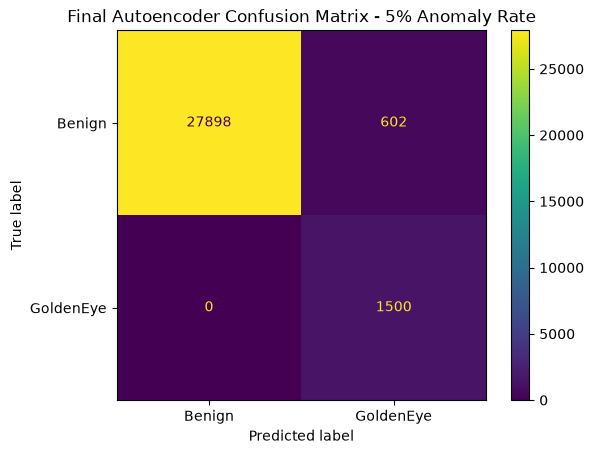

In [159]:
cm = confusion_matrix(
    y_final_5,
    final_5_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Benign",
        "GoldenEye"
    ]
)

disp.plot()

plt.title(
    "Final Autoencoder Confusion Matrix - 5% Anomaly Rate"
)

plt.show()

## Final Classification Report - 5% Anomaly Test

In [160]:
print(
    classification_report(
        y_final_5,
        final_5_pred,
        target_names=[
            "Benign",
            "GoldenEye"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     1.0000    0.9789    0.9893     28500
   GoldenEye     0.7136    1.0000    0.8329      1500

    accuracy                         0.9799     30000
   macro avg     0.8568    0.9894    0.9111     30000
weighted avg     0.9857    0.9799    0.9815     30000



### Observation

On the final 5% anomaly holdout set, the optimized Autoencoder detects all GoldenEye attacks, achieving Recall of 1.0000 and an F1-score of 0.8329.

The Precision of 0.7136 indicates that some benign flows are still classified as anomalous, but the model prioritizes attack detection with zero missed GoldenEye samples.

# Final Experiment Summary

In [161]:
final_summary = pd.DataFrame([
    {
        "Experiment": "Exp 1",
        "Configuration": "All Features, No HPO",
        "Best Model": "Autoencoder",
        "5% F1": ae_results_df.loc[
            ae_results_df["Test Set"] == "5%",
            "F1-Score"
        ].values[0]
    },
    {
        "Experiment": "Exp 2",
        "Configuration": "Selected Features, No HPO",
        "Best Model": "Autoencoder",
        "5% F1": ae_selected_results_df.loc[
            ae_selected_results_df["Test Set"] == "5%",
            "F1-Score"
        ].values[0]
    },
    {
        "Experiment": "Exp 3",
        "Configuration": "All Features + Optuna",
        "Best Model": "Autoencoder",
        "5% F1": best_ae_hpo_results_df.loc[
            best_ae_hpo_results_df["HPO Set"] == "5%",
            "F1-Score"
        ].values[0]
    },
    {
        "Experiment": "Exp 4",
        "Configuration": "Selected Features + Optuna",
        "Best Model": "Autoencoder",
        "5% F1": ae_selected_hpo_results_df.loc[
            ae_selected_hpo_results_df["HPO Set"] == "5%",
            "F1-Score"
        ].values[0]
    }
])

final_summary.round(4)

,Experiment,Configuration,Best Model,5% F1
0,Exp 1,"All Features, No HPO",Autoencoder,0.2844
1,Exp 2,"Selected Features, No HPO",Autoencoder,0.4877
2,Exp 3,All Features + Optuna,Autoencoder,0.8396
3,Exp 4,Selected Features + Optuna,Autoencoder,0.6447


### Observation

The Autoencoder is the strongest model across the experimental configurations.

Correlation filtering improves the untuned Autoencoder substantially, while the best overall development performance is obtained by the Optuna-optimized Autoencoder using all cleaned features.

## Final Holdout Results

In [162]:
final_ae_results_df.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
0,0.2%,Autoencoder - Final,0.9786,0.0856,1.0,0.1577,0.0214,0.0
1,1%,Autoencoder - Final,0.9789,0.3212,1.0,0.4862,0.0213,0.0
2,5%,Autoencoder - Final,0.9799,0.7136,1.0,0.8329,0.0211,0.0


## Final 5% Test Result

In [163]:
final_5_result = final_ae_results_df[
    final_ae_results_df["Test Set"] == "5%"
]

final_5_result.round(4)

,Test Set,Model,Accuracy,Precision,Recall,F1-Score,FPR,FNR
2,5%,Autoencoder - Final,0.9799,0.7136,1.0,0.8329,0.0211,0.0


### Final Observation

On the final 5% anomaly holdout set, the optimized Autoencoder achieves an F1-score of 0.8329 with Recall of 1.0000.

All 1,500 GoldenEye attacks are detected. The Precision of 0.7136 indicates that some benign flows are incorrectly flagged as anomalous, reflecting the expected trade-off between maximizing attack detection and limiting false alarms.

## Save Results

In [164]:
RESULTS_PATH = Path("../results")
RESULTS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

experiment_1_results.to_csv(
    RESULTS_PATH / "medium2_experiment1_baseline.csv",
    index=False
)

experiment_2_results.to_csv(
    RESULTS_PATH / "medium2_experiment2_selected_features.csv",
    index=False
)

hpo_model_comparison.to_csv(
    RESULTS_PATH / "medium2_hpo_comparison.csv",
    index=False
)

final_ae_results_df.to_csv(
    RESULTS_PATH / "medium2_final_autoencoder_results.csv",
    index=False
)

final_summary.to_csv(
    RESULTS_PATH / "medium2_experiment_summary.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


## Save Selected Features

In [165]:
selected_features_df = pd.DataFrame({
    "Selected Feature": selected_features
})

selected_features_df.to_csv(
    RESULTS_PATH / "medium2_selected_features.csv",
    index=False
)

print(
    "Selected features saved:",
    len(selected_features)
)

Selected features saved: 43


## Best Autoencoder Hyperparameters

In [166]:
best_ae_parameters = pd.DataFrame([
    {
        "encoding_dim": ae_study.best_params["encoding_dim"],
        "hidden_dim": ae_study.best_params["hidden_dim"],
        "n_hidden_layers": ae_study.best_params["n_hidden_layers"],
        "learning_rate": ae_study.best_params["learning_rate"],
        "dropout": ae_study.best_params["dropout"],
        "l2": ae_study.best_params["l2"],
        "batch_size": ae_study.best_params["batch_size"],
        "target_fpr": ae_study.best_params["target_fpr"]
    }
])

best_ae_parameters

,encoding_dim,hidden_dim,n_hidden_layers,learning_rate,dropout,l2,batch_size,target_fpr
0,8,128,2,0.000585,0.014766,2.501534e-07,1024,0.019343


In [167]:
best_ae_parameters.to_csv(
    RESULTS_PATH / "medium2_best_autoencoder_parameters.csv",
    index=False
)

# Conclusion

This experiment evaluated unsupervised anomaly detection on the CSE-CIC-IDS2018 dataset using Benign traffic as normal behaviour and DoS-GoldenEye traffic as anomalous behaviour.

Four models were investigated: Multivariate Gaussian, Isolation Forest, One-Class SVM and Autoencoder.

The baseline statistical and classical anomaly detectors showed limited attack separation. The Autoencoder performed considerably better because reconstruction error provided a stronger distinction between benign and GoldenEye traffic.

Correlation-based feature reduction improved the baseline Autoencoder from an F1-score of 0.2844 to 0.4877 at the 5% anomaly rate.

Optuna hyperparameter optimization further improved anomaly detection. The strongest development configuration was the Autoencoder trained on all cleaned features.

The final model was evaluated on previously unused holdout data. At the 5% anomaly rate, it achieved an F1-score of 0.8329, Precision of 0.7136 and Recall of 1.0000, successfully detecting all GoldenEye attacks in the final test set.

The results demonstrate that deep reconstruction-based anomaly detection is considerably more effective than the evaluated classical unsupervised methods for detecting GoldenEye attacks in this dataset.